In [62]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_14.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_11.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_eval_01.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_08.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_13.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_01.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_test_00.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_10.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_09.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_07.tfrecord
/k

In [63]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print("\n📁", root)
    for file in files:
        print("   📄", file)


📁 /kaggle/input

📁 /kaggle/input/datasets

📁 /kaggle/input/datasets/fantineh

📁 /kaggle/input/datasets/fantineh/next-day-wildfire-spread
   📄 next_day_wildfire_spread_train_14.tfrecord
   📄 next_day_wildfire_spread_train_11.tfrecord
   📄 next_day_wildfire_spread_eval_01.tfrecord
   📄 next_day_wildfire_spread_train_08.tfrecord
   📄 next_day_wildfire_spread_train_13.tfrecord
   📄 next_day_wildfire_spread_train_01.tfrecord
   📄 next_day_wildfire_spread_test_00.tfrecord
   📄 next_day_wildfire_spread_train_10.tfrecord
   📄 next_day_wildfire_spread_train_09.tfrecord
   📄 next_day_wildfire_spread_train_07.tfrecord
   📄 next_day_wildfire_spread_train_12.tfrecord
   📄 next_day_wildfire_spread_train_04.tfrecord
   📄 next_day_wildfire_spread_train_02.tfrecord
   📄 next_day_wildfire_spread_eval_00.tfrecord
   📄 next_day_wildfire_spread_train_03.tfrecord
   📄 next_day_wildfire_spread_train_06.tfrecord
   📄 next_day_wildfire_spread_train_00.tfrecord
   📄 next_day_wildfire_spread_train_05.tfrecord
 

In [64]:
import tensorflow as tf
import numpy as np

print(tf.__version__)

2.20.0


In [65]:
import glob

train_files = sorted(
    glob.glob("/kaggle/input/**/*.tfrecord", recursive=True)
)

print("Number of TFRecord files:", len(train_files))

for f in train_files:
    print(f)

Number of TFRecord files: 19
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_eval_00.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_eval_01.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_test_00.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_test_01.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_00.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_01.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_02.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_03.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_04.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_

In [66]:
train_files = [
    f for f in train_files
    if "train" in f
]

print("Training files:", len(train_files))

Training files: 15


In [67]:
dataset = tf.data.TFRecordDataset(train_files[0])

for raw_record in dataset.take(1):

    example = tf.train.Example()
    example.ParseFromString(raw_record.numpy())

    print("Features:")
    
    for name, feature in example.features.feature.items():
        values = feature.float_list.value
        
        print(
            f"{name:15s} → {len(values)} values"
        )

Features:
NDVI            → 4096 values
tmmn            → 4096 values
elevation       → 4096 values
population      → 4096 values
FireMask        → 4096 values
vs              → 4096 values
pdsi            → 4096 values
pr              → 4096 values
tmmx            → 4096 values
sph             → 4096 values
th              → 4096 values
PrevFireMask    → 4096 values
erc             → 4096 values


In [68]:
dataset = tf.data.TFRecordDataset(train_files[0])

for raw_record in dataset.take(1):

    example = tf.train.Example()
    example.ParseFromString(raw_record.numpy())

    print("Features:")
    
    for name, feature in example.features.feature.items():
        values = feature.float_list.value
        
        print(
            f"{name:15s} → {len(values)} values"
        )

Features:
NDVI            → 4096 values
tmmn            → 4096 values
elevation       → 4096 values
population      → 4096 values
FireMask        → 4096 values
vs              → 4096 values
pdsi            → 4096 values
pr              → 4096 values
tmmx            → 4096 values
sph             → 4096 values
th              → 4096 values
PrevFireMask    → 4096 values
erc             → 4096 values


In [69]:
dataset = tf.data.TFRecordDataset(train_files[0])

for raw_record in dataset.take(1):

    example = tf.train.Example()
    example.ParseFromString(raw_record.numpy())

    print("Features:")
    
    for name, feature in example.features.feature.items():
        values = feature.float_list.value
        
        print(
            f"{name:15s} → {len(values)} values"
        )

Features:
NDVI            → 4096 values
tmmn            → 4096 values
elevation       → 4096 values
population      → 4096 values
FireMask        → 4096 values
vs              → 4096 values
pdsi            → 4096 values
pr              → 4096 values
tmmx            → 4096 values
sph             → 4096 values
th              → 4096 values
PrevFireMask    → 4096 values
erc             → 4096 values


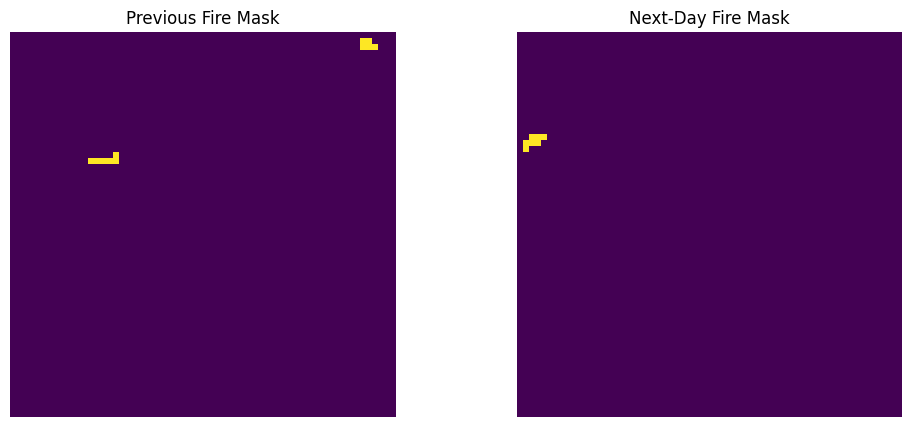

In [70]:
import matplotlib.pyplot as plt

for raw_record in dataset.take(1):

    example = tf.train.Example()
    example.ParseFromString(raw_record.numpy())

    elevation = np.array(
        example.features.feature["elevation"].float_list.value
    ).reshape(64, 64)

    fire = np.array(
        example.features.feature["FireMask"].float_list.value
    ).reshape(64, 64)

    prev_fire = np.array(
        example.features.feature["PrevFireMask"].float_list.value
    ).reshape(64, 64)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(prev_fire)
plt.title("Previous Fire Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(fire)
plt.title("Next-Day Fire Mask")
plt.axis("off")

plt.show()

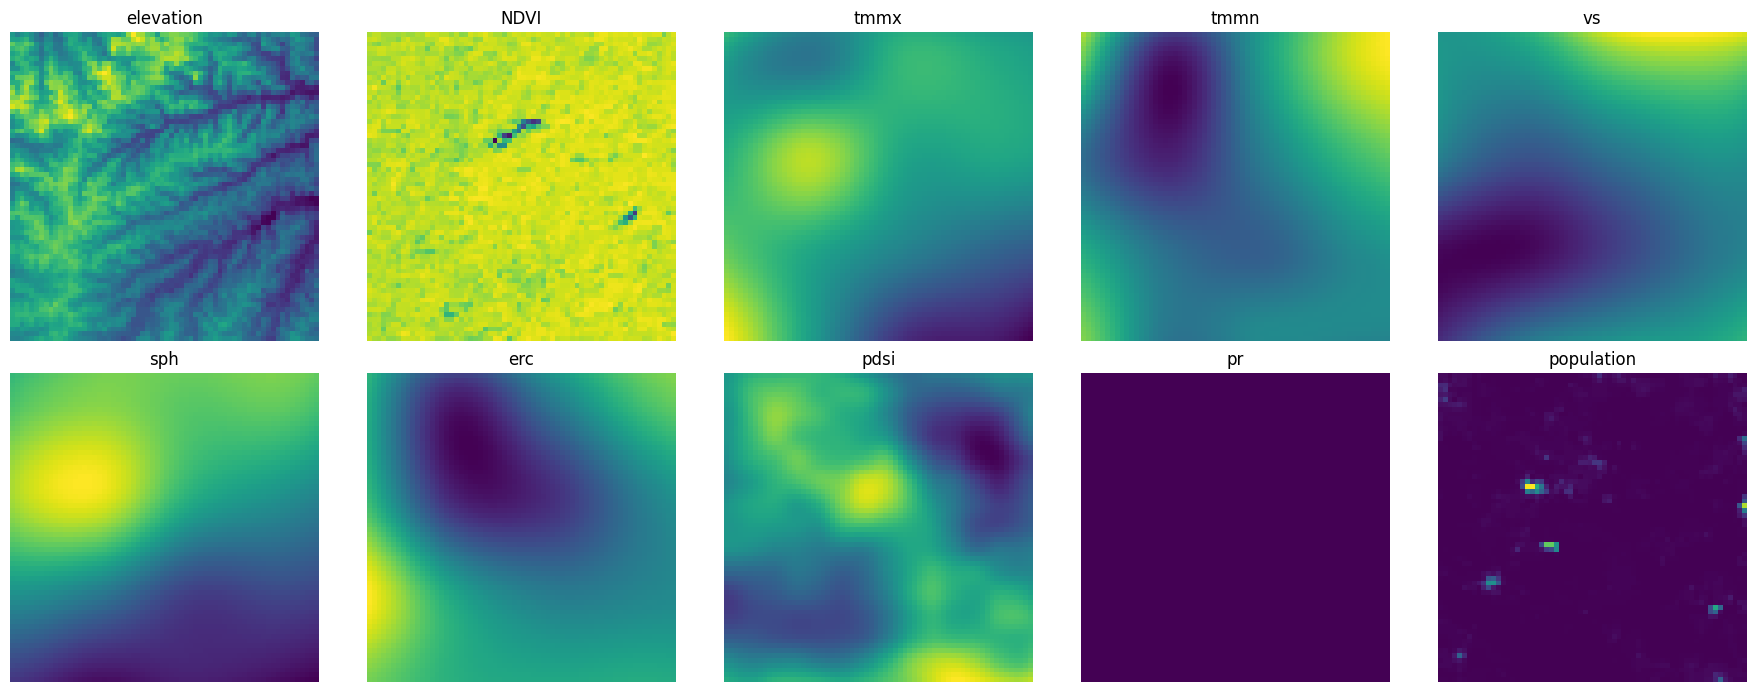

In [71]:
features_to_plot = [
    "elevation",
    "NDVI",
    "tmmx",
    "tmmn",
    "vs",
    "sph",
    "erc",
    "pdsi",
    "pr",
    "population"
]

fig, axes = plt.subplots(2, 5, figsize=(18, 7))

for ax, feature_name in zip(axes.flat, features_to_plot):

    values = np.array(
        example.features.feature[feature_name].float_list.value
    )

    data = values.reshape(64, 64)

    im = ax.imshow(data)
    ax.set_title(feature_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [72]:
INPUT_FEATURES = [
    "erc",
    "sph",
    "th",
    "population",
    "elevation",
    "tmmn",
    "pr",
    "NDVI",
    "pdsi",
    "PrevFireMask",
    "vs",
    "tmmx"
]

TARGET = "FireMask"

In [73]:
import glob

train_files = sorted(
    glob.glob("/kaggle/input/**/*.tfrecord", recursive=True)
)

train_files = [f for f in train_files if "train" in f]

print("Training files:", len(train_files))

for f in train_files:
    print(f)

Training files: 15
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_00.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_01.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_02.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_03.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_04.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_05.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_06.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_07.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_08.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread

In [74]:
import tensorflow as tf
import numpy as np
import glob

train_files = sorted(
    glob.glob("/kaggle/input/**/*.tfrecord", recursive=True)
)

train_files = [f for f in train_files if "train" in f]

print("Training files:", len(train_files))

dataset = tf.data.TFRecordDataset(train_files[0])

for raw_record in dataset.take(1):
    example = tf.train.Example()
    example.ParseFromString(raw_record.numpy())

print("Sample loaded!")

Training files: 15
Sample loaded!


In [75]:
fire = np.array(
    example.features.feature["FireMask"].float_list.value
)

prev_fire = np.array(
    example.features.feature["PrevFireMask"].float_list.value
)

print("FireMask shape:", fire.shape)
print("FireMask unique values:", np.unique(fire, return_counts=True))

print()

print("PrevFireMask shape:", prev_fire.shape)
print("PrevFireMask unique values:", np.unique(prev_fire, return_counts=True))

FireMask shape: (4096,)
FireMask unique values: (array([0., 1.]), array([4089,    7]))

PrevFireMask shape: (4096,)
PrevFireMask unique values: (array([0., 1.]), array([4085,   11]))


In [76]:
import tensorflow as tf
import numpy as np
import glob

# Find all TFRecord files in the Kaggle input directory
train_files = sorted(
    glob.glob("/kaggle/input/**/*.tfrecord", recursive=True)
)

# Keep only the training files
train_files = [f for f in train_files if "train" in f]

print("Training files:", len(train_files))

# Open the first training TFRecord file
dataset = tf.data.TFRecordDataset(train_files[0])

# Take only ONE sample
for raw_record in dataset.take(1):

    # Create an empty TensorFlow Example
    example = tf.train.Example()

    # Decode the raw TFRecord data
    example.ParseFromString(raw_record.numpy())

print("Sample loaded successfully!")

Training files: 15
Sample loaded successfully!


In [77]:
fire = np.array(
    example.features.feature["FireMask"].float_list.value
)

prev_fire = np.array(
    example.features.feature["PrevFireMask"].float_list.value
)

print("FireMask shape:", fire.shape)
print("FireMask values:", np.unique(fire, return_counts=True))

print()

print("PrevFireMask shape:", prev_fire.shape)
print("PrevFireMask values:", np.unique(prev_fire, return_counts=True))

FireMask shape: (4096,)
FireMask values: (array([0., 1.]), array([4089,    7]))

PrevFireMask shape: (4096,)
PrevFireMask values: (array([0., 1.]), array([4085,   11]))


In [78]:
import tensorflow as tf
import numpy as np
import glob

train_files = sorted(
    glob.glob("/kaggle/input/**/*.tfrecord", recursive=True)
)

train_files = [
    f for f in train_files
    if "train" in f
]

print("Training files:", len(train_files))

dataset = tf.data.TFRecordDataset(train_files[0])

for raw_record in dataset.take(1):
    example = tf.train.Example()
    example.ParseFromString(raw_record.numpy())

print("Sample loaded successfully!")

Training files: 15
Sample loaded successfully!


In [79]:
# ============================================================
# STEP 1: LOAD ONE TRAINING SAMPLE
# ============================================================

# TensorFlow:
# We use TensorFlow because the dataset is stored as TFRecord files.
import tensorflow as tf

# NumPy:
# We will use NumPy later to inspect and manipulate the data.
import numpy as np

# Glob:
# This helps us search for all .tfrecord files inside Kaggle's
# input directory.
import glob


# ------------------------------------------------------------
# Find all TFRecord files
# ------------------------------------------------------------

# "/kaggle/input/**/*.tfrecord"
# means:
#   - Start searching inside /kaggle/input
#   - Look inside all folders
#   - Find every file ending with .tfrecord
#
# recursive=True allows glob to search through subfolders.
train_files = sorted(
    glob.glob("/kaggle/input/**/*.tfrecord", recursive=True)
)


# ------------------------------------------------------------
# Keep ONLY the training files
# ------------------------------------------------------------

# Our dataset also has evaluation and test files.
# We don't want those right now.
#
# This line keeps files whose filename/path contains "train".
train_files = [
    f for f in train_files
    if "train" in f
]


# Print how many training files were found.
# We expect this to be 15:
#
# train_00
# train_01
# ...
# train_14
#
# Total = 15
print("Training files:", len(train_files))


# ------------------------------------------------------------
# Open the first training TFRecord
# ------------------------------------------------------------

# train_files[0] means the FIRST training file.
#
# TFRecordDataset allows TensorFlow to read the file
# without loading the entire ~4 GB dataset into RAM.
dataset = tf.data.TFRecordDataset(train_files[0])


# ------------------------------------------------------------
# Read ONLY ONE sample
# ------------------------------------------------------------

# dataset.take(1) means:
# "Give me only the first record/sample."
#
# We are deliberately NOT reading the entire file.
# At this stage, we only want to understand what ONE sample
# looks like.
for raw_record in dataset.take(1):

    # Create an empty TensorFlow Example object.
    #
    # A TFRecord contains serialized data.
    # tf.train.Example is the structure used to decode it.
    example = tf.train.Example()

    # raw_record is still serialized/binary data.
    #
    # .numpy() converts it to a NumPy byte representation.
    #
    # ParseFromString() decodes that data into "example".
    example.ParseFromString(raw_record.numpy())


# If we reach here, one sample has been successfully loaded.
print("Sample loaded successfully!")

Training files: 15
Sample loaded successfully!


In [80]:
# ============================================================
# STEP 2: INSPECT THE FIRE MASKS
# ============================================================

# ------------------------------------------------------------
# Extract the TARGET fire mask
# ------------------------------------------------------------

# "FireMask" is the fire mask for the NEXT DAY.
#
# This is what our U-Net will eventually try to predict.
#
# The dataset stores it as a flattened list of numbers,
# so right now it will contain 4096 values.
fire = np.array(
    example.features.feature["FireMask"].float_list.value
)


# ------------------------------------------------------------
# Extract the PREVIOUS-DAY fire mask
# ------------------------------------------------------------

# "PrevFireMask" represents the fire situation at the
# previous time step.
#
# This will be one of our INPUT features.
prev_fire = np.array(
    example.features.feature["PrevFireMask"].float_list.value
)


# ------------------------------------------------------------
# Check the shapes
# ------------------------------------------------------------

# We expect:
#
# 4096 values
#      ↓
# 64 × 64 spatial grid
#
# We are checking this BEFORE reshaping anything.
print("FireMask shape:", fire.shape)
print("PrevFireMask shape:", prev_fire.shape)


# ------------------------------------------------------------
# Check what values exist in FireMask
# ------------------------------------------------------------

# np.unique() finds every different value in the array.
#
# return_counts=True also tells us how many pixels contain
# each value.
#
# THIS IS VERY IMPORTANT.
#
# We don't want to blindly assume:
#     0 = no fire
#     1 = fire
#
# We first want to see what the actual dataset contains.
fire_values, fire_counts = np.unique(
    fire,
    return_counts=True
)

print("\nFireMask values:")
for value, count in zip(fire_values, fire_counts):
    print(f"  Value {value}: {count} pixels")


# ------------------------------------------------------------
# Do the same thing for PrevFireMask
# ------------------------------------------------------------

prev_values, prev_counts = np.unique(
    prev_fire,
    return_counts=True
)

print("\nPrevFireMask values:")
for value, count in zip(prev_values, prev_counts):
    print(f"  Value {value}: {count} pixels")

FireMask shape: (4096,)
PrevFireMask shape: (4096,)

FireMask values:
  Value 0.0: 4089 pixels
  Value 1.0: 7 pixels

PrevFireMask values:
  Value 0.0: 4085 pixels
  Value 1.0: 11 pixels


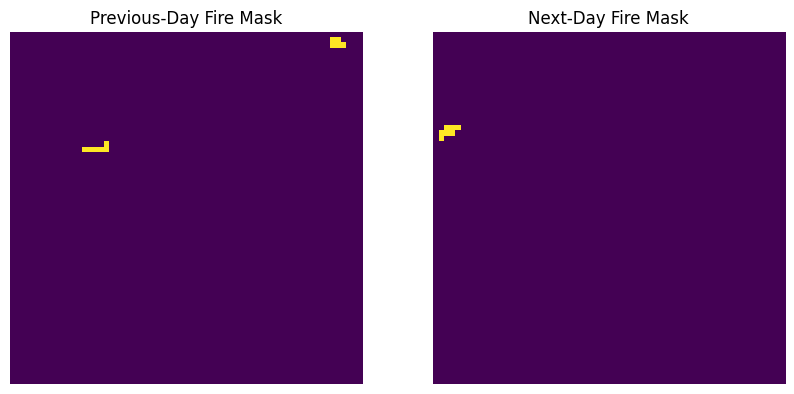

In [81]:
import matplotlib.pyplot as plt

# Convert the flattened 4096 values into a 64 × 64 spatial grid
fire_image = fire.reshape(64, 64)
prev_fire_image = prev_fire.reshape(64, 64)

# Display previous-day and next-day fire masks side by side
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(prev_fire_image)
plt.title("Previous-Day Fire Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(fire_image)
plt.title("Next-Day Fire Mask")
plt.axis("off")

plt.show()

In [82]:
# Features that will potentially be used as inputs
input_features = [
    "tmmn",
    "tmmx",
    "pr",
    "NDVI",
    "pdsi",
    "erc",
    "elevation",
    "population",
    "sph",
    "vs",
    "th"
]

# Print basic statistics for every feature
for feature_name in input_features:
    
    values = np.array(
        example.features.feature[feature_name].float_list.value
    )
    
    print(
        f"{feature_name:12s} | "
        f"min: {values.min():10.4f} | "
        f"max: {values.max():10.4f} | "
        f"mean: {values.mean():10.4f} | "
        f"shape: {values.shape}"
    )

tmmn         | min:   275.1861 | max:   276.4624 | mean:   275.7385 | shape: (4096,)
tmmx         | min:   292.3449 | max:   293.4912 | mean:   292.9763 | shape: (4096,)
pr           | min:     0.0000 | max:     0.0000 | mean:     0.0000 | shape: (4096,)
NDVI         | min: -2604.0000 | max:  8548.0000 | mean:  7520.2361 | shape: (4096,)
pdsi         | min:     2.4609 | max:     4.9886 | mean:     3.7183 | shape: (4096,)
erc          | min:    18.4246 | max:    23.1834 | mean:    20.4636 | shape: (4096,)
elevation    | min:    36.0000 | max:   141.0000 | mean:    85.0276 | shape: (4096,)
population   | min:     0.0000 | max:   741.3262 | mean:     8.4262 | shape: (4096,)
sph          | min:     0.0044 | max:     0.0047 | mean:     0.0046 | shape: (4096,)
vs           | min:     2.8368 | max:     3.3268 | mean:     3.0286 | shape: (4096,)
th           | min:   160.4904 | max:   190.2577 | mean:   174.2338 | shape: (4096,)


In [83]:
# Check several training samples instead of only one.
# This helps us see whether the unusual values we saw
# are specific to one sample or common throughout the dataset.

features_to_check = [
    "tmmn",
    "tmmx",
    "pr",
    "NDVI",
    "pdsi",
    "erc",
    "elevation",
    "population",
    "sph",
    "vs",
    "th"
]

# Store the values from multiple samples for each feature
feature_values = {
    feature: [] for feature in features_to_check
}

# Read the first 100 samples from the training file
for raw_record in dataset.take(100):

    # Decode the TFRecord sample
    example_temp = tf.train.Example()
    example_temp.ParseFromString(raw_record.numpy())

    # Extract every feature we want to inspect
    for feature_name in features_to_check:

        values = np.array(
            example_temp.features.feature[feature_name].float_list.value
        )

        feature_values[feature_name].extend(values)


# Print statistics across all 100 samples
print("Statistics across 100 training samples:\n")

for feature_name in features_to_check:

    values = np.array(feature_values[feature_name])

    print(
        f"{feature_name:12s} | "
        f"min: {values.min():10.4f} | "
        f"max: {values.max():10.4f} | "
        f"mean: {values.mean():10.4f} | "
        f"std: {values.std():10.4f}"
    )

Statistics across 100 training samples:

tmmn         | min:   258.3073 | max:   295.7216 | mean:   280.6075 | std:     7.7087
tmmx         | min:   272.8949 | max:   312.7018 | mean:   296.4775 | std:     7.7215
pr           | min:    -0.6234 | max:    42.9499 | mean:     0.7324 | std:     2.9378
NDVI         | min: -5586.0000 | max:  9917.0000 | mean:  5625.2645 | std:  2090.2679
pdsi         | min:    -5.7113 | max:     7.5153 | mean:    -0.3458 | std:     2.4843
erc          | min:     9.5339 | max:    97.3343 | mean:    42.1489 | std:    18.5558
elevation    | min:    16.0000 | max:  2917.0000 | mean:   922.6598 | std:   862.3491
population   | min:     0.0000 | max:  6521.0840 | mean:    17.2139 | std:   128.5332
sph          | min:     0.0014 | max:     0.0175 | mean:     0.0065 | std:     0.0037
vs           | min:     1.1498 | max:     7.6061 | mean:     3.6111 | std:     1.1459
th           | min: -465921.5000 | max: 37735.6289 | mean:    30.2749 | std:  6957.6311


In [84]:
# Check the unusual values in NDVI and wind direction (th).
# We want to know whether the extreme numbers occur frequently
# or are just a small number of special/invalid pixels.

for feature_name in ["NDVI", "th"]:

    values = np.array(feature_values[feature_name])

    print(f"\n========== {feature_name} ==========")

    # Show the 20 smallest values
    print("\n20 smallest values:")
    print(np.sort(values)[:20])

    # Show the 20 largest values
    print("\n20 largest values:")
    print(np.sort(values)[-20:])

    # Count how many values are extremely large/small.
    # These thresholds are ONLY for investigation.
    # We are NOT changing the data yet.
    if feature_name == "NDVI":
        suspicious = np.abs(values) > 2000
    else:
        suspicious = np.abs(values) > 360

    print(
        f"\nSuspicious values: {suspicious.sum()} "
        f"out of {len(values)} "
        f"({100 * suspicious.mean():.4f}%)"
    )


========== NDVI ==========

20 smallest values:
[-5586. -5586. -5210. -5158. -5059. -4606. -4606. -4509. -4464. -4265.
 -4078. -4056. -4056. -3980. -3973. -3973. -3958. -3954. -3954. -3862.]

20 largest values:
[9698. 9700. 9708. 9709. 9717. 9718. 9735. 9735. 9742. 9743. 9761. 9761.
 9763. 9767. 9788. 9817. 9837. 9873. 9893. 9917.]

Suspicious values: 395765 out of 409600 (96.6223%)

========== th ==========

20 smallest values:
[-465921.5     -463106.4375  -463084.28125 -454987.65625 -454945.4375
 -444072.9375  -442089.59375 -442029.375   -441389.8125  -441368.65625
 -433651.5625  -433611.25    -424936.71875 -424860.59375 -421358.0625
 -421300.5625  -418619.03125 -416089.65625 -416069.6875  -408794.71875]

20 largest values:
[35280.84375    35330.34765625 35333.671875   35814.6796875
 35818.0546875  36137.07421875 36139.46875    36354.79296875
 36357.2265625  36778.640625   36779.953125   36853.265625
 36855.73828125 37000.25390625 37001.5859375  37002.16015625
 37225.13671875 37507.

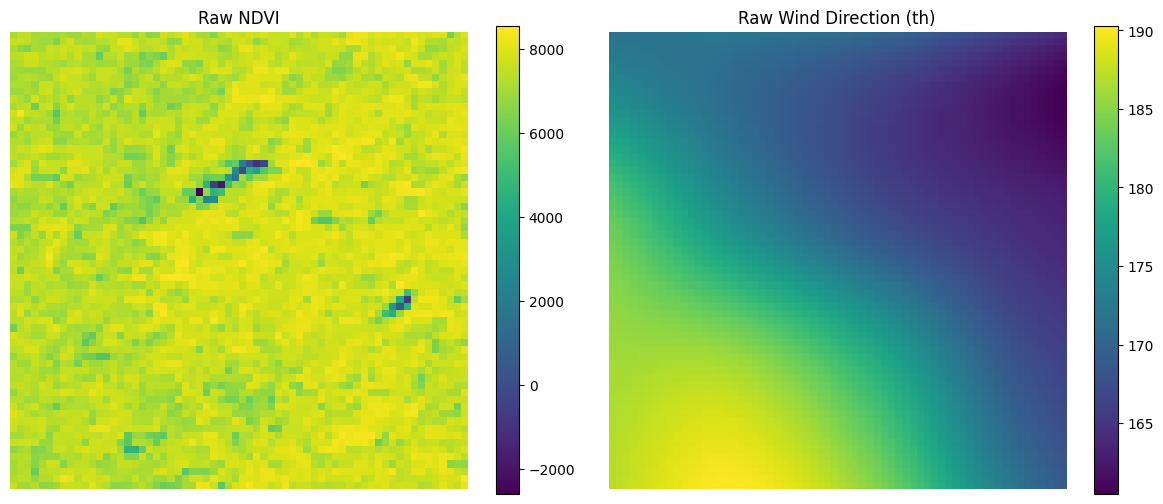

NDVI:
  Min : -2604.0
  Max : 8548.0
  Mean: 7520.236083984375

th:
  Min : 160.4904327392578
  Max : 190.2576904296875
  Mean: 174.23384880647063


In [85]:
# We're visualizing NDVI and wind direction from ONE sample.
# This helps us understand whether the extreme values are
# isolated pixels, entire regions, or a consistent encoding.

# Read one sample again
for raw_record in dataset.take(1):
    example_check = tf.train.Example()
    example_check.ParseFromString(raw_record.numpy())

# Extract NDVI and th
ndvi = np.array(
    example_check.features.feature["NDVI"].float_list.value
).reshape(64, 64)

th = np.array(
    example_check.features.feature["th"].float_list.value
).reshape(64, 64)

# Create two visualizations
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(ndvi)
plt.title("Raw NDVI")
plt.colorbar()
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(th)
plt.title("Raw Wind Direction (th)")
plt.colorbar()
plt.axis("off")

plt.tight_layout()
plt.show()

# Also print basic statistics for this particular sample
print("NDVI:")
print("  Min :", ndvi.min())
print("  Max :", ndvi.max())
print("  Mean:", ndvi.mean())

print("\nth:")
print("  Min :", th.min())
print("  Max :", th.max())
print("  Mean:", th.mean())

In [86]:
import os

# Kaggle stores datasets that you add to your notebook
# inside the /kaggle/input/ directory.
#
# This will show us the exact folder and files available there.

for root, dirs, files in os.walk("/kaggle/input"):
    print("\nFolder:", root)

    for file in files:
        print("   ", file)


Folder: /kaggle/input

Folder: /kaggle/input/datasets

Folder: /kaggle/input/datasets/fantineh

Folder: /kaggle/input/datasets/fantineh/next-day-wildfire-spread
    next_day_wildfire_spread_train_14.tfrecord
    next_day_wildfire_spread_train_11.tfrecord
    next_day_wildfire_spread_eval_01.tfrecord
    next_day_wildfire_spread_train_08.tfrecord
    next_day_wildfire_spread_train_13.tfrecord
    next_day_wildfire_spread_train_01.tfrecord
    next_day_wildfire_spread_test_00.tfrecord
    next_day_wildfire_spread_train_10.tfrecord
    next_day_wildfire_spread_train_09.tfrecord
    next_day_wildfire_spread_train_07.tfrecord
    next_day_wildfire_spread_train_12.tfrecord
    next_day_wildfire_spread_train_04.tfrecord
    next_day_wildfire_spread_train_02.tfrecord
    next_day_wildfire_spread_eval_00.tfrecord
    next_day_wildfire_spread_train_03.tfrecord
    next_day_wildfire_spread_train_06.tfrecord
    next_day_wildfire_spread_train_00.tfrecord
    next_day_wildfire_spread_train_05.tfre

In [87]:
import tensorflow as tf
import numpy as np

# ------------------------------------------------------------
# Features that will be used as input to U-Net
# ------------------------------------------------------------

INPUT_FEATURES = [
    "PrevFireMask",
    "tmmn",
    "tmmx",
    "pr",
    "NDVI",
    "pdsi",
    "erc",
    "elevation",
    "population",
    "sph",
    "vs",
    "th"
]

# This is the value we want the model to predict
TARGET = "FireMask"


# ------------------------------------------------------------
# Function to decode ONE TFRecord sample
# ------------------------------------------------------------

def parse_tfrecord(raw_record):

    # Create an empty TensorFlow Example
    example = tf.train.Example()

    # Convert the raw TFRecord bytes into readable features
    example.ParseFromString(raw_record.numpy())

    # --------------------------------------------------------
    # Extract the input features
    # --------------------------------------------------------

    # Each feature is currently stored as a flattened
    # array of 4096 values.
    #
    # 4096 = 64 × 64
    #
    # We reshape each feature back into its spatial 64×64 form.
    feature_arrays = []

    for feature_name in INPUT_FEATURES:

        values = np.array(
            example.features.feature[feature_name].float_list.value,
            dtype=np.float32
        )

        values = values.reshape(64, 64)

        feature_arrays.append(values)


    # --------------------------------------------------------
    # Stack all input features together
    # --------------------------------------------------------

    # Before stacking:
    #
    # feature_arrays =
    # [
    #   (64,64),   # PrevFireMask
    #   (64,64),   # tmmn
    #   (64,64),   # tmmx
    #   ...
    # ]
    #
    # After stacking:
    #
    # X = (12, 64, 64)
    #
    # This is the format PyTorch Conv2D/U-Net expects.
    X = np.stack(feature_arrays, axis=0)


    # --------------------------------------------------------
    # Extract the target FireMask
    # --------------------------------------------------------

    target = np.array(
        example.features.feature[TARGET].float_list.value,
        dtype=np.float32
    )

    # Convert 4096 values → 64×64
    target = target.reshape(64, 64)

    # Add a channel dimension:
    #
    # (64,64) → (1,64,64)
    #
    # This gives us one output channel for the fire mask.
    Y = target[np.newaxis, :, :]


    return X, Y

In [88]:
# Take one raw sample from the first training file
for raw_record in dataset.take(1):

    X, Y = parse_tfrecord(raw_record)

# Check that the shapes are what we expect
print("Input X shape :", X.shape)
print("Target Y shape:", Y.shape)

# Also check the data types
print("Input X dtype :", X.dtype)
print("Target Y dtype:", Y.dtype)

Input X shape : (12, 64, 64)
Target Y shape: (1, 64, 64)
Input X dtype : float32
Target Y dtype: float32


In [89]:
# We will calculate mean and standard deviation for every
# numerical input feature.
#
# We are using 100 training samples for now so this runs quickly.
# Later, once the pipeline is verified, we can calculate the
# final statistics using the complete training dataset.

normalization_values = {
    feature: []
    for feature in INPUT_FEATURES
    if feature != "PrevFireMask"
}

# Read 100 training samples
for raw_record in dataset.take(100):

    # Decode the TFRecord
    example_temp = tf.train.Example()
    example_temp.ParseFromString(raw_record.numpy())

    # Collect values for each numerical feature
    for feature_name in normalization_values:

        values = np.array(
            example_temp.features.feature[feature_name].float_list.value,
            dtype=np.float32
        )

        normalization_values[feature_name].extend(values)


# Calculate mean and standard deviation
feature_stats = {}

for feature_name, values in normalization_values.items():

    values = np.array(values, dtype=np.float32)

    mean = values.mean()
    std = values.std()

    # Prevent division by zero if a feature happens
    # to have zero variance.
    if std < 1e-8:
        std = 1.0

    feature_stats[feature_name] = {
        "mean": mean,
        "std": std
    }


# Display the statistics
print("Normalization statistics:\n")

for feature_name, stats in feature_stats.items():

    print(
        f"{feature_name:12s} | "
        f"mean = {stats['mean']:10.4f} | "
        f"std = {stats['std']:10.4f}"
    )

Normalization statistics:

tmmn         | mean =   280.6075 | std =     7.7087
tmmx         | mean =   296.4774 | std =     7.7215
pr           | mean =     0.7324 | std =     2.9378
NDVI         | mean =  5625.2651 | std =  2090.2681
pdsi         | mean =    -0.3458 | std =     2.4843
erc          | mean =    42.1489 | std =    18.5558
elevation    | mean =   922.6601 | std =   862.3491
population   | mean =    17.2139 | std =   128.5332
sph          | mean =     0.0065 | std =     0.0037
vs           | mean =     3.6111 | std =     1.1459
th           | mean =    30.2749 | std =  6957.6309


In [90]:
# Calculate preliminary clipping limits for each numerical feature.
#
# The NDWS paper clips extreme values before calculating
# normalization statistics.
#
# For this initial inspection, we use the 0.1th and 99.9th
# percentiles from our 100 training samples.
#
# IMPORTANT:
# These are preliminary values for understanding the data.
# Later, we will calculate the FINAL values using the complete
# training dataset.

clip_stats = {}

for feature_name in INPUT_FEATURES:

    # PrevFireMask is a binary mask, so we don't clip it.
    if feature_name == "PrevFireMask":
        continue

    values = np.array(
        normalization_values[feature_name],
        dtype=np.float32
    )

    # Find the lower 0.1% boundary
    lower = np.percentile(values, 0.1)

    # Find the upper 99.9% boundary
    upper = np.percentile(values, 99.9)

    clip_stats[feature_name] = {
        "lower": lower,
        "upper": upper
    }

    print(
        f"{feature_name:12s} | "
        f"lower = {lower:12.4f} | "
        f"upper = {upper:12.4f}"
    )

tmmn         | lower =     258.6194 | upper =     295.5214
tmmx         | lower =     273.2204 | upper =     312.4146
pr           | lower =      -0.1733 | upper =      34.0736
NDVI         | lower =    -497.6087 | upper =    9276.0000
pdsi         | lower =      -5.1879 | upper =       6.5478
erc          | lower =      11.0204 | upper =      97.0156
elevation    | lower =      26.0000 | upper =    2781.0000
population   | lower =       0.0000 | upper =    2021.9189
sph          | lower =       0.0015 | upper =       0.0173
vs           | lower =       1.2220 | upper =       7.4801
th           | lower =  -20267.6680 | upper =   11910.5479


In [91]:
# We are checking the physical/expected ranges of the features.
#
# This is NOT changing the data yet.
# We are simply comparing the values in our training samples
# against reasonable physical limits.
#
# This will help us decide what should be clipped before
# calculating the final normalization statistics.

physical_ranges = {
    "tmmn": (250, 330),       # Minimum temperature, Kelvin
    "tmmx": (250, 330),       # Maximum temperature, Kelvin
    "pr": (0, 100),           # Precipitation
    "NDVI": (-2000, 10000),   # Raw NDVI product range
    "pdsi": (-15, 15),        # Drought index
    "erc": (0, 150),          # Energy Release Component
    "elevation": (-100, 5000),
    "population": (0, 20000),
    "sph": (0, 0.03),         # Specific humidity
    "vs": (0, 20),            # Wind speed
    "th": (-360, 360)         # Wind direction in degrees
}

print("Checking values against physical ranges:\n")

for feature_name, (lower, upper) in physical_ranges.items():

    values = np.array(
        normalization_values[feature_name],
        dtype=np.float32
    )

    # Find values below the expected minimum
    below = np.sum(values < lower)

    # Find values above the expected maximum
    above = np.sum(values > upper)

    total = len(values)

    print(
        f"{feature_name:12s} | "
        f"below range: {below:7d} | "
        f"above range: {above:7d} | "
        f"total: {total:7d}"
    )

Checking values against physical ranges:

tmmn         | below range:       0 | above range:       0 | total:  409600
tmmx         | below range:       0 | above range:       0 | total:  409600
pr           | below range:   48653 | above range:       0 | total:  409600
NDVI         | below range:      98 | above range:       0 | total:  409600
pdsi         | below range:       0 | above range:       0 | total:  409600
erc          | below range:       0 | above range:       0 | total:  409600
elevation    | below range:       0 | above range:       0 | total:  409600
population   | below range:       0 | above range:       0 | total:  409600
sph          | below range:       0 | above range:       0 | total:  409600
vs           | below range:       0 | above range:       0 | total:  409600
th           | below range:     710 | above range:     876 | total:  409600


In [92]:
import numpy as np

In [93]:
# This block checks exactly how many values would be changed
# by our initial cleaning rules.
#
# IMPORTANT:
# We are NOT modifying the dataset yet.
# We're only measuring the effect of the cleaning.

# ------------------------------------------------------------
# Precipitation
# ------------------------------------------------------------

pr_values = np.array(
    normalization_values["pr"],
    dtype=np.float32
)

# Precipitation cannot be negative.
pr_invalid = pr_values < 0

print(
    "Precipitation values to clip:",
    pr_invalid.sum()
)


# ------------------------------------------------------------
# NDVI
# ------------------------------------------------------------

ndvi_values = np.array(
    normalization_values["NDVI"],
    dtype=np.float32
)

# NDVI in this dataset is stored as a scaled integer-like value.
# For now, we'll inspect values outside the observed reasonable
# range before deciding the exact transformation.
ndvi_invalid = (ndvi_values < -2000) | (ndvi_values > 10000)

print(
    "NDVI values outside expected range:",
    ndvi_invalid.sum()
)


# ------------------------------------------------------------
# Wind direction
# ------------------------------------------------------------

th_values = np.array(
    normalization_values["th"],
    dtype=np.float32
)

# A wind direction represented in degrees should fall between
# -360 and +360 before we convert it into a circular/vector form.
th_invalid = (th_values < -360) | (th_values > 360)

print(
    "Wind direction values outside expected range:",
    th_invalid.sum()
)

Precipitation values to clip: 48653
NDVI values outside expected range: 98
Wind direction values outside expected range: 1586


In [94]:
import numpy as np

# Precipitation
pr_values = np.array(normalization_values["pr"], dtype=np.float32)
pr_negative = pr_values[pr_values < 0]

print("=== PRECIPITATION ===")
print("Negative count:", len(pr_negative))
print("Negative min:", pr_negative.min())
print("Negative max:", pr_negative.max())
print("Negative percentiles:",
      np.percentile(pr_negative, [0, 1, 10, 25, 50, 75, 90, 99, 100]))

print("\nOverall percentiles:")
print(np.percentile(pr_values, [0, 0.1, 1, 5, 50, 95, 99, 99.9, 100]))


# Wind direction
th_values = np.array(normalization_values["th"], dtype=np.float32)

th_valid = th_values[(th_values >= -360) & (th_values <= 360)]

print("\n=== WIND DIRECTION ===")
print("Valid count:", len(th_valid))
print("Invalid count:", len(th_values) - len(th_valid))
print("Valid min:", th_valid.min())
print("Valid max:", th_valid.max())
print("Valid percentiles:",
      np.percentile(th_valid, [0, 1, 5, 25, 50, 75, 95, 99, 100]))


# NDVI
ndvi_values = np.array(normalization_values["NDVI"], dtype=np.float32)

ndvi_invalid = ndvi_values[
    (ndvi_values < -2000) | (ndvi_values > 10000)
]

print("\n=== NDVI ===")
print("Invalid count:", len(ndvi_invalid))
print("Invalid values:", np.unique(ndvi_invalid)[:30])

=== PRECIPITATION ===
Negative count: 48653
Negative min: -0.6233595
Negative max: -2.4681272e-13
Negative percentiles: [-6.23359501e-01 -1.59106461e-01 -2.46694479e-02 -7.95901660e-03
 -2.22087489e-03 -4.05870873e-04 -5.86314629e-05 -3.93044509e-08
 -2.46812716e-13]

Overall percentiles:
[-6.23359501e-01 -1.73326922e-01 -2.94433795e-02 -3.39870242e-03
  0.00000000e+00  3.56175119e+00  1.50768243e+01  3.40735707e+01
  4.29499435e+01]

=== WIND DIRECTION ===
Valid count: 408014
Invalid count: 1586
Valid min: -356.62866
Valid max: 353.69012
Valid percentiles: [-356.62866211   47.49472153   68.71647835  126.98280716  185.73630524
  250.02490616  300.2963974   314.52386902  353.69012451]

=== NDVI ===
Invalid count: 98
Invalid values: [-5586. -5210. -5158. -5059. -4606. -4509. -4464. -4265. -4078. -4056.
 -3980. -3973. -3958. -3954. -3862. -3738. -3692. -3537. -3529. -3488.
 -3412. -3364. -3321. -3307. -3293. -3232. -3215. -3174. -3120. -3008.]


In [95]:
import numpy as np

def clean_features(features):
    features = features.copy()

    # Precipitation: negative values are physically invalid
    features["pr"] = np.maximum(features["pr"], 0.0)

    # NDVI: clip to valid raw product range
    features["NDVI"] = np.clip(features["NDVI"], -2000.0, 10000.0)

    # Wind direction: remove physically impossible values
    features["th"] = np.clip(features["th"], -360.0, 360.0)

    return features

In [97]:
# This checks the actual Kaggle input directory and prints the available
# wildfire TFRecord files so we use the correct paths.

import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if "wildfire" in file.lower() or file.endswith(".tfrecord"):
            print(os.path.join(root, file))

/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_14.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_11.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_eval_01.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_08.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_13.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_01.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_test_00.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_10.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_09.tfrecord
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_07.tfrecord
/k

In [98]:
# This creates the list of all 15 training TFRecord files using the
# actual Kaggle dataset location.

TRAIN_DIR = "/kaggle/input/datasets/fantineh/next-day-wildfire-spread"

TRAIN_FILES = [
    os.path.join(
        TRAIN_DIR,
        f"next_day_wildfire_spread_train_{i:02d}.tfrecord"
    )
    for i in range(15)
]

print("Training files:", len(TRAIN_FILES))

for f in TRAIN_FILES:
    print(f, "->", os.path.exists(f))

Training files: 15
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_00.tfrecord -> True
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_01.tfrecord -> True
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_02.tfrecord -> True
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_03.tfrecord -> True
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_04.tfrecord -> True
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_05.tfrecord -> True
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_06.tfrecord -> True
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_07.tfrecord -> True
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_08.tfrecord -> True
/kaggle/i

In [101]:
# This lists the actual folders and files mounted under /kaggle/input.
# It does not try to open any TFRecord.

import os

for root, dirs, files in os.walk("/kaggle/input"):
    print("\nFOLDER:", root)

    if files:
        for file in files[:20]:
            print("  ", file)


FOLDER: /kaggle/input

FOLDER: /kaggle/input/datasets

FOLDER: /kaggle/input/datasets/fantineh

FOLDER: /kaggle/input/datasets/fantineh/next-day-wildfire-spread
   next_day_wildfire_spread_train_14.tfrecord
   next_day_wildfire_spread_train_11.tfrecord
   next_day_wildfire_spread_eval_01.tfrecord
   next_day_wildfire_spread_train_08.tfrecord
   next_day_wildfire_spread_train_13.tfrecord
   next_day_wildfire_spread_train_01.tfrecord
   next_day_wildfire_spread_test_00.tfrecord
   next_day_wildfire_spread_train_10.tfrecord
   next_day_wildfire_spread_train_09.tfrecord
   next_day_wildfire_spread_train_07.tfrecord
   next_day_wildfire_spread_train_12.tfrecord
   next_day_wildfire_spread_train_04.tfrecord
   next_day_wildfire_spread_train_02.tfrecord
   next_day_wildfire_spread_eval_00.tfrecord
   next_day_wildfire_spread_train_03.tfrecord
   next_day_wildfire_spread_train_06.tfrecord
   next_day_wildfire_spread_train_00.tfrecord
   next_day_wildfire_spread_train_05.tfrecord
   next_day_w

In [102]:
# This creates the correct list of the 15 training TFRecord files
# from the actual Kaggle-mounted dataset directory.

import os

TRAIN_DIR = "/kaggle/input/datasets/fantineh/next-day-wildfire-spread"

TRAIN_FILES = [
    os.path.join(
        TRAIN_DIR,
        f"next_day_wildfire_spread_train_{i:02d}.tfrecord"
    )
    for i in range(15)
]

print("Training files:", len(TRAIN_FILES))

for file_path in TRAIN_FILES:
    print(
        os.path.basename(file_path),
        "->",
        os.path.exists(file_path)
    )

Training files: 15
next_day_wildfire_spread_train_00.tfrecord -> True
next_day_wildfire_spread_train_01.tfrecord -> True
next_day_wildfire_spread_train_02.tfrecord -> True
next_day_wildfire_spread_train_03.tfrecord -> True
next_day_wildfire_spread_train_04.tfrecord -> True
next_day_wildfire_spread_train_05.tfrecord -> True
next_day_wildfire_spread_train_06.tfrecord -> True
next_day_wildfire_spread_train_07.tfrecord -> True
next_day_wildfire_spread_train_08.tfrecord -> True
next_day_wildfire_spread_train_09.tfrecord -> True
next_day_wildfire_spread_train_10.tfrecord -> True
next_day_wildfire_spread_train_11.tfrecord -> True
next_day_wildfire_spread_train_12.tfrecord -> True
next_day_wildfire_spread_train_13.tfrecord -> True
next_day_wildfire_spread_train_14.tfrecord -> True


In [103]:
# This verifies that TensorFlow can actually read the first training
# TFRecord before we perform the expensive full-dataset statistics scan.

import tensorflow as tf

test_dataset = tf.data.TFRecordDataset(
    TRAIN_FILES[0]
)

first_record = next(iter(test_dataset))

print("Successfully read:")
print(TRAIN_FILES[0])
print("Record size:", len(first_record.numpy()), "bytes")

Successfully read:
/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_train_00.tfrecord
Record size: 213297 bytes


In [106]:
# This calculates normalization statistics from all 15 training TFRecords
# using the exact filenames and directory mounted by Kaggle.

import tensorflow as tf
import numpy as np
import os


# ============================================================
# 1. CORRECT DATASET PATH
# ============================================================

TRAIN_DIR = "/kaggle/input/datasets/fantineh/next-day-wildfire-spread"


TRAIN_FILES = [
    os.path.join(
        TRAIN_DIR,
        f"next_day_wildfire_spread_train_{i:02d}.tfrecord"
    )
    for i in range(15)
]


# ============================================================
# 2. VERIFY FILES BEFORE READING
# ============================================================

print("Checking training files...\n")

for file_path in TRAIN_FILES:

    if not os.path.exists(file_path):
        raise FileNotFoundError(
            f"File not found:\n{file_path}"
        )

    print("✓", os.path.basename(file_path))


print("\nTotal training files:", len(TRAIN_FILES))


# ============================================================
# 3. FEATURES
# ============================================================

CONTINUOUS_FEATURES = [
    "tmmn",
    "tmmx",
    "pr",
    "NDVI",
    "pdsi",
    "erc",
    "elevation",
    "population",
    "sph",
    "vs",
    "th"
]


FEATURE_DESCRIPTION = {
    feature: tf.io.FixedLenFeature(
        [4096],
        tf.float32
    )
    for feature in [
        "tmmn",
        "tmmx",
        "pr",
        "NDVI",
        "pdsi",
        "erc",
        "elevation",
        "population",
        "sph",
        "vs",
        "th",
        "PrevFireMask",
        "FireMask"
    ]
}


def parse_example(example):

    return tf.io.parse_single_example(
        example,
        FEATURE_DESCRIPTION
    )


# ============================================================
# 4. ONLINE STATISTICS
# ============================================================

stats = {
    feature: {
        "sum": 0.0,
        "sum_sq": 0.0,
        "count": 0
    }
    for feature in CONTINUOUS_FEATURES
}


# ============================================================
# 5. SCAN ALL TRAINING FILES
# ============================================================

for file_path in TRAIN_FILES:

    print(
        "\nProcessing:",
        os.path.basename(file_path)
    )

    dataset = tf.data.TFRecordDataset(
        file_path
    )

    for raw_example in dataset:

        example = parse_example(
            raw_example
        )

        for feature in CONTINUOUS_FEATURES:

            values = (
                example[feature]
                .numpy()
                .astype(np.float64)
            )

            # -----------------------------
            # Cleaning
            # -----------------------------

            if feature == "pr":

                values = np.maximum(
                    values,
                    0.0
                )

            elif feature == "NDVI":

                values = np.clip(
                    values,
                    -2000.0,
                    10000.0
                )

            elif feature == "th":

                values = np.clip(
                    values,
                    -360.0,
                    360.0
                )

            # -----------------------------
            # Online statistics
            # -----------------------------

            stats[feature]["sum"] += values.sum()

            stats[feature]["sum_sq"] += np.square(
                values
            ).sum()

            stats[feature]["count"] += values.size


# ============================================================
# 6. CALCULATE MEAN / STD
# ============================================================

normalization_stats = {}


for feature in CONTINUOUS_FEATURES:

    s = stats[feature]["sum"]
    ss = stats[feature]["sum_sq"]
    n = stats[feature]["count"]

    mean = s / n

    variance = (
        ss / n
    ) - (mean ** 2)

    std = np.sqrt(
        max(variance, 1e-12)
    )

    normalization_stats[feature] = {
        "mean": mean,
        "std": std
    }


# ============================================================
# 7. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 70)
print("FINAL TRAINING NORMALIZATION STATISTICS")
print("=" * 70)

for feature in CONTINUOUS_FEATURES:

    mean = normalization_stats[feature]["mean"]
    std = normalization_stats[feature]["std"]

    print(
        f"{feature:<12} | "
        f"mean: {mean:12.6f} | "
        f"std: {std:12.6f}"
    )

Checking training files...

✓ next_day_wildfire_spread_train_00.tfrecord
✓ next_day_wildfire_spread_train_01.tfrecord
✓ next_day_wildfire_spread_train_02.tfrecord
✓ next_day_wildfire_spread_train_03.tfrecord
✓ next_day_wildfire_spread_train_04.tfrecord
✓ next_day_wildfire_spread_train_05.tfrecord
✓ next_day_wildfire_spread_train_06.tfrecord
✓ next_day_wildfire_spread_train_07.tfrecord
✓ next_day_wildfire_spread_train_08.tfrecord
✓ next_day_wildfire_spread_train_09.tfrecord
✓ next_day_wildfire_spread_train_10.tfrecord
✓ next_day_wildfire_spread_train_11.tfrecord
✓ next_day_wildfire_spread_train_12.tfrecord
✓ next_day_wildfire_spread_train_13.tfrecord
✓ next_day_wildfire_spread_train_14.tfrecord

Total training files: 15

Processing: next_day_wildfire_spread_train_00.tfrecord

Processing: next_day_wildfire_spread_train_01.tfrecord

Processing: next_day_wildfire_spread_train_02.tfrecord

Processing: next_day_wildfire_spread_train_03.tfrecord

Processing: next_day_wildfire_spread_train_04.

In [107]:
import tensorflow as tf
import numpy as np
import os

TRAIN_DIR = "/kaggle/input/datasets/fantineh/next-day-wildfire-spread"

TRAIN_FILES = [
    os.path.join(
        TRAIN_DIR,
        f"next_day_wildfire_spread_train_{i:02d}.tfrecord"
    )
    for i in range(15)
]

CONTINUOUS_FEATURES = [
    "tmmn",
    "tmmx",
    "pr",
    "NDVI",
    "pdsi",
    "erc",
    "elevation",
    "population",
    "sph",
    "vs",
    "th"
]

FEATURE_DESCRIPTION = {
    feature: tf.io.FixedLenFeature([4096], tf.float32)
    for feature in [
        "tmmn",
        "tmmx",
        "pr",
        "NDVI",
        "pdsi",
        "erc",
        "elevation",
        "population",
        "sph",
        "vs",
        "th",
        "PrevFireMask",
        "FireMask"
    ]
}


def parse_example(example):
    return tf.io.parse_single_example(
        example,
        FEATURE_DESCRIPTION
    )


stats = {
    feature: {
        "sum": 0.0,
        "sum_sq": 0.0,
        "count": 0
    }
    for feature in CONTINUOUS_FEATURES
}


for file_path in TRAIN_FILES:

    print("Processing:", os.path.basename(file_path))

    dataset = tf.data.TFRecordDataset(file_path)

    for raw_example in dataset:

        example = parse_example(raw_example)

        for feature in CONTINUOUS_FEATURES:

            values = example[feature].numpy().astype(np.float64)

            if feature == "pr":
                values = np.maximum(values, 0.0)

            elif feature == "NDVI":
                values = np.clip(values, -2000.0, 10000.0)

            elif feature == "th":
                values = np.clip(values, -360.0, 360.0)

            stats[feature]["sum"] += values.sum()
            stats[feature]["sum_sq"] += np.square(values).sum()
            stats[feature]["count"] += values.size


normalization_stats = {}

for feature in CONTINUOUS_FEATURES:

    s = stats[feature]["sum"]
    ss = stats[feature]["sum_sq"]
    n = stats[feature]["count"]

    mean = s / n
    variance = (ss / n) - (mean ** 2)
    std = np.sqrt(max(variance, 1e-12))

    normalization_stats[feature] = {
        "mean": mean,
        "std": std
    }


print("\n" + "=" * 70)
print("FINAL TRAINING NORMALIZATION STATISTICS")
print("=" * 70)

for feature in CONTINUOUS_FEATURES:

    mean = normalization_stats[feature]["mean"]
    std = normalization_stats[feature]["std"]

    print(
        f"{feature:<12} | "
        f"mean: {mean:12.6f} | "
        f"std: {std:12.6f}"
    )

Processing: next_day_wildfire_spread_train_00.tfrecord
Processing: next_day_wildfire_spread_train_01.tfrecord
Processing: next_day_wildfire_spread_train_02.tfrecord
Processing: next_day_wildfire_spread_train_03.tfrecord
Processing: next_day_wildfire_spread_train_04.tfrecord
Processing: next_day_wildfire_spread_train_05.tfrecord
Processing: next_day_wildfire_spread_train_06.tfrecord
Processing: next_day_wildfire_spread_train_07.tfrecord
Processing: next_day_wildfire_spread_train_08.tfrecord
Processing: next_day_wildfire_spread_train_09.tfrecord
Processing: next_day_wildfire_spread_train_10.tfrecord
Processing: next_day_wildfire_spread_train_11.tfrecord
Processing: next_day_wildfire_spread_train_12.tfrecord
Processing: next_day_wildfire_spread_train_13.tfrecord
Processing: next_day_wildfire_spread_train_14.tfrecord

FINAL TRAINING NORMALIZATION STATISTICS
tmmn         | mean:   281.852110 | std:    18.497169
tmmx         | mean:   297.716643 | std:    19.458073
pr           | mean:     0

In [108]:
import tensorflow as tf
import numpy as np
import os

TRAIN_DIR = "/kaggle/input/datasets/fantineh/next-day-wildfire-spread"

TRAIN_FILES = [
    os.path.join(
        TRAIN_DIR,
        f"next_day_wildfire_spread_train_{i:02d}.tfrecord"
    )
    for i in range(15)
]

FEATURE_DESCRIPTION = {
    "FireMask": tf.io.FixedLenFeature([4096], tf.float32)
}


total_pixels = 0
fire_pixels = 0
no_fire_pixels = 0
unknown_pixels = 0

unique_values = set()

for file_path in TRAIN_FILES:

    print("Processing:", os.path.basename(file_path))

    dataset = tf.data.TFRecordDataset(file_path)

    for raw_example in dataset:

        example = tf.io.parse_single_example(
            raw_example,
            FEATURE_DESCRIPTION
        )

        mask = example["FireMask"].numpy()

        unique_values.update(np.unique(mask).tolist())

        total_pixels += mask.size
        fire_pixels += np.sum(mask == 1)
        no_fire_pixels += np.sum(mask == 0)

        # Check for uncertain/unknown labels
        unknown_pixels += np.sum(mask < 0)


print("\n" + "=" * 60)
print("FIRE MASK STATISTICS")
print("=" * 60)

print("Unique values found:", sorted(unique_values))

print(f"\nTotal pixels:       {total_pixels:,}")
print(f"No-fire pixels:     {no_fire_pixels:,}")
print(f"Fire pixels:        {fire_pixels:,}")
print(f"Unknown pixels:     {unknown_pixels:,}")

print("\nPercentages:")
print(f"No-fire:            {100 * no_fire_pixels / total_pixels:.4f}%")
print(f"Fire:               {100 * fire_pixels / total_pixels:.4f}%")
print(f"Unknown:            {100 * unknown_pixels / total_pixels:.4f}%")

if fire_pixels > 0:
    print(
        f"\nNo-fire / Fire ratio: "
        f"{no_fire_pixels / fire_pixels:.2f}:1"
    )

Processing: next_day_wildfire_spread_train_00.tfrecord
Processing: next_day_wildfire_spread_train_01.tfrecord
Processing: next_day_wildfire_spread_train_02.tfrecord
Processing: next_day_wildfire_spread_train_03.tfrecord
Processing: next_day_wildfire_spread_train_04.tfrecord
Processing: next_day_wildfire_spread_train_05.tfrecord
Processing: next_day_wildfire_spread_train_06.tfrecord
Processing: next_day_wildfire_spread_train_07.tfrecord
Processing: next_day_wildfire_spread_train_08.tfrecord
Processing: next_day_wildfire_spread_train_09.tfrecord
Processing: next_day_wildfire_spread_train_10.tfrecord
Processing: next_day_wildfire_spread_train_11.tfrecord
Processing: next_day_wildfire_spread_train_12.tfrecord
Processing: next_day_wildfire_spread_train_13.tfrecord
Processing: next_day_wildfire_spread_train_14.tfrecord

FIRE MASK STATISTICS
Unique values found: [-1.0, 0.0, 1.0]

Total pixels:       61,353,984
No-fire pixels:     59,254,803
Fire pixels:        658,270
Unknown pixels:     1,44

In [109]:
import tensorflow as tf
import numpy as np
import os

TRAIN_DIR = "/kaggle/input/datasets/fantineh/next-day-wildfire-spread"

TRAIN_FILES = [
    os.path.join(
        TRAIN_DIR,
        f"next_day_wildfire_spread_train_{i:02d}.tfrecord"
    )
    for i in range(15)
]

FEATURE_DESCRIPTION = {
    "PrevFireMask": tf.io.FixedLenFeature([4096], tf.float32)
}


total_pixels = 0
fire_pixels = 0
no_fire_pixels = 0
unknown_pixels = 0

unique_values = set()

for file_path in TRAIN_FILES:

    print("Processing:", os.path.basename(file_path))

    dataset = tf.data.TFRecordDataset(file_path)

    for raw_example in dataset:

        example = tf.io.parse_single_example(
            raw_example,
            FEATURE_DESCRIPTION
        )

        mask = example["PrevFireMask"].numpy()

        unique_values.update(np.unique(mask).tolist())

        total_pixels += mask.size
        fire_pixels += np.sum(mask == 1)
        no_fire_pixels += np.sum(mask == 0)
        unknown_pixels += np.sum(mask < 0)


print("\n" + "=" * 60)
print("PREVIOUS FIRE MASK STATISTICS")
print("=" * 60)

print("Unique values found:", sorted(unique_values))

print(f"\nTotal pixels:       {total_pixels:,}")
print(f"No-fire pixels:     {no_fire_pixels:,}")
print(f"Fire pixels:        {fire_pixels:,}")
print(f"Unknown pixels:     {unknown_pixels:,}")

print("\nPercentages:")
print(f"No-fire:            {100 * no_fire_pixels / total_pixels:.4f}%")
print(f"Fire:               {100 * fire_pixels / total_pixels:.4f}%")
print(f"Unknown:            {100 * unknown_pixels / total_pixels:.4f}%")

if fire_pixels > 0:
    print(
        f"\nNo-fire / Fire ratio: "
        f"{no_fire_pixels / fire_pixels:.2f}:1"
    )

Processing: next_day_wildfire_spread_train_00.tfrecord
Processing: next_day_wildfire_spread_train_01.tfrecord
Processing: next_day_wildfire_spread_train_02.tfrecord
Processing: next_day_wildfire_spread_train_03.tfrecord
Processing: next_day_wildfire_spread_train_04.tfrecord
Processing: next_day_wildfire_spread_train_05.tfrecord
Processing: next_day_wildfire_spread_train_06.tfrecord
Processing: next_day_wildfire_spread_train_07.tfrecord
Processing: next_day_wildfire_spread_train_08.tfrecord
Processing: next_day_wildfire_spread_train_09.tfrecord
Processing: next_day_wildfire_spread_train_10.tfrecord
Processing: next_day_wildfire_spread_train_11.tfrecord
Processing: next_day_wildfire_spread_train_12.tfrecord
Processing: next_day_wildfire_spread_train_13.tfrecord
Processing: next_day_wildfire_spread_train_14.tfrecord

PREVIOUS FIRE MASK STATISTICS
Unique values found: [-1.0, 0.0, 1.0]

Total pixels:       61,353,984
No-fire pixels:     60,179,816
Fire pixels:        503,555
Unknown pixels:

In [110]:
import os
import tensorflow as tf
import torch
from torch.utils.data import IterableDataset, DataLoader


DATA_DIR = "/kaggle/input/datasets/fantineh/next-day-wildfire-spread"


TRAIN_FILES = [
    os.path.join(
        DATA_DIR,
        f"next_day_wildfire_spread_train_{i:02d}.tfrecord"
    )
    for i in range(15)
]

EVAL_FILES = [
    os.path.join(
        DATA_DIR,
        f"next_day_wildfire_spread_eval_{i:02d}.tfrecord"
    )
    for i in range(2)
]


FEATURE_DESCRIPTION = {
    "PrevFireMask": tf.io.FixedLenFeature([4096], tf.float32),
    "FireMask": tf.io.FixedLenFeature([4096], tf.float32),
}


class WildfireDataset(IterableDataset):

    def __init__(self, files):
        super().__init__()
        self.files = files

    def parse_example(self, example):
        return tf.io.parse_single_example(
            example,
            FEATURE_DESCRIPTION
        )

    def __iter__(self):

        for file_path in self.files:

            dataset = tf.data.TFRecordDataset(file_path)

            for raw_example in dataset:

                example = self.parse_example(raw_example)

                prev_fire = example["PrevFireMask"].numpy()
                target = example["FireMask"].numpy()

                prev_fire = prev_fire.reshape(64, 64)
                target = target.reshape(64, 64)

                # Input: unknown previous-fire pixels become 0
                prev_fire = np.where(
                    prev_fire == -1,
                    0,
                    prev_fire
                )

                # Target validity mask
                valid = target != -1

                # Convert target into binary labels
                target = np.where(
                    target == 1,
                    1.0,
                    0.0
                )

                X = torch.tensor(
                    prev_fire,
                    dtype=torch.float32
                ).unsqueeze(0)

                Y = torch.tensor(
                    target,
                    dtype=torch.float32
                ).unsqueeze(0)

                valid_mask = torch.tensor(
                    valid,
                    dtype=torch.bool
                ).unsqueeze(0)

                yield X, Y, valid_mask


train_dataset = WildfireDataset(TRAIN_FILES)
eval_dataset = WildfireDataset(EVAL_FILES)


train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    num_workers=0
)

eval_loader = DataLoader(
    eval_dataset,
    batch_size=16,
    num_workers=0
)


X, Y, valid = next(iter(train_loader))

print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("Valid mask shape:", valid.shape)

print("X dtype:", X.dtype)
print("Y dtype:", Y.dtype)
print("Valid dtype:", valid.dtype)

X shape: torch.Size([16, 1, 64, 64])
Y shape: torch.Size([16, 1, 64, 64])
Valid mask shape: torch.Size([16, 1, 64, 64])
X dtype: torch.float32
Y dtype: torch.float32
Valid dtype: torch.bool


In [111]:
X, Y, valid = next(iter(train_loader))

print("Shapes")
print("X:", X.shape)
print("Y:", Y.shape)
print("Valid:", valid.shape)

print("\nInput values:")
print(torch.unique(X))

print("\nTarget values:")
print(torch.unique(Y))

print("\nValid mask values:")
print(torch.unique(valid))

print("\nFirst batch statistics")
print("Previous fire pixels:", (X == 1).sum().item())
print("Target fire pixels:", (Y == 1).sum().item())
print("Unknown target pixels:", (~valid).sum().item())

valid_target = Y[valid]

if len(valid_target) > 0:
    print(
        "Target fire percentage among valid pixels:",
        100 * (valid_target == 1).float().mean().item(),
        "%"
    )

Shapes
X: torch.Size([16, 1, 64, 64])
Y: torch.Size([16, 1, 64, 64])
Valid: torch.Size([16, 1, 64, 64])

Input values:
tensor([0., 1.])

Target values:
tensor([0., 1.])

Valid mask values:
tensor([False,  True])

First batch statistics
Previous fire pixels: 119
Target fire pixels: 41
Unknown target pixels: 122
Target fire percentage among valid pixels: 0.06267771241255105 %


In [112]:
# This defines exactly which information each experiment is allowed to use.
# Keeping these groups explicit prevents accidental feature leakage between models.

MODEL_1_FEATURES = [
    "PrevFireMask"
]

MODEL_2_FEATURES = [
    "PrevFireMask",
    "tmmn",
    "tmmx",
    "pr",
    "sph",
    "vs",
    "th"
]

MODEL_3_FEATURES = [
    "PrevFireMask",
    "tmmn",
    "tmmx",
    "pr",
    "sph",
    "vs",
    "th",
    "NDVI",
    "pdsi",
    "erc",
    "elevation",
    "population"
]

print("Model 1:", MODEL_1_FEATURES)
print("Model 2:", MODEL_2_FEATURES)
print("Model 3:", MODEL_3_FEATURES)

Model 1: ['PrevFireMask']
Model 2: ['PrevFireMask', 'tmmn', 'tmmx', 'pr', 'sph', 'vs', 'th']
Model 3: ['PrevFireMask', 'tmmn', 'tmmx', 'pr', 'sph', 'vs', 'th', 'NDVI', 'pdsi', 'erc', 'elevation', 'population']


In [113]:
# This function cleans the raw environmental variables and converts
# wind direction into circular sin/cos representations.

TRAIN_STATS = {
    "tmmn": (281.852110, 18.497169),
    "tmmx": (297.716643, 19.458073),
    "pr": (0.324562, 1.532254),
    "NDVI": (5355.635208, 2165.629625),
    "pdsi": (-0.772871, 2.440719),
    "erc": (53.469103, 25.097984),
    "elevation": (896.571320, 842.610351),
    "population": (30.460330, 214.200051),
    "sph": (0.006526, 0.003736),
    "vs": (3.627848, 1.309215),
}


def normalize_feature(x, name):
    mean, std = TRAIN_STATS[name]
    return (x - mean) / (std + 1e-8)


def preprocess_features(features):
    features = features.copy()

    # Cleaning
    features["pr"] = np.maximum(features["pr"], 0.0)

    features["NDVI"] = np.clip(
        features["NDVI"],
        -2000.0,
        10000.0
    )

    features["th"] = np.clip(
        features["th"],
        -360.0,
        360.0
    )

    # Normalize scalar features
    for name in TRAIN_STATS:
        features[name] = normalize_feature(
            features[name],
            name
        )

    # Circular wind-direction encoding
    theta = np.deg2rad(features["th"])

    features["th_sin"] = np.sin(theta)
    features["th_cos"] = np.cos(theta)

    return features

In [114]:
# This Dataset reads the TFRecords and dynamically builds the input tensor
# according to the selected model's feature group.

import tensorflow as tf
import torch
from torch.utils.data import IterableDataset


ALL_FEATURES = [
    "tmmn",
    "FireMask",
    "population",
    "tmmx",
    "erc",
    "pdsi",
    "elevation",
    "vs",
    "sph",
    "PrevFireMask",
    "th",
    "NDVI",
    "pr"
]


FEATURES_TO_PARSE = {
    feature: tf.io.FixedLenFeature([64 * 64], tf.float32)
    for feature in ALL_FEATURES
}


class WildfireDataset(IterableDataset):

    def __init__(
        self,
        files,
        input_features
    ):
        self.files = files
        self.input_features = input_features

    def parse_example(self, example):

        parsed = tf.io.parse_single_example(
            example,
            FEATURES_TO_PARSE
        )

        features = {
            key: parsed[key].numpy()
            for key in ALL_FEATURES
        }

        features = preprocess_features(features)

        # --------------------------------------------------
        # Build input channels
        # --------------------------------------------------

        channels = []

        for feature in self.input_features:

            if feature == "th":

                # We don't use raw wind direction.
                channels.append(features["th_sin"])
                channels.append(features["th_cos"])

            elif feature == "PrevFireMask":

                # Unknown previous-fire pixels are currently treated
                # as no-fire for the input.
                prev_fire = features["PrevFireMask"].copy()

                prev_fire[prev_fire == -1] = 0

                channels.append(prev_fire)

            else:

                channels.append(features[feature])

        X = np.stack(channels, axis=0)

        # --------------------------------------------------
        # Target
        # --------------------------------------------------

        target = features["FireMask"]

        # Unknown target pixels must NOT become negative examples.
        valid = target != -1

        Y = np.where(
            target == 1,
            1.0,
            0.0
        )

        X = X.reshape(-1, 64, 64)
        Y = Y.reshape(1, 64, 64)
        valid = valid.reshape(1, 64, 64)

        return (
            torch.tensor(X, dtype=torch.float32),
            torch.tensor(Y, dtype=torch.float32),
            torch.tensor(valid, dtype=torch.bool)
        )

    def __iter__(self):

        for file in self.files:

            dataset = tf.data.TFRecordDataset(
                file
            )

            for raw_record in dataset:

                yield self.parse_example(
                    raw_record
                )

In [115]:
# This creates separate DataLoaders for the three experiments.
# The underlying samples remain identical; only the available input
# features change.

from torch.utils.data import DataLoader


dataset_1 = WildfireDataset(
    TRAIN_FILES,
    MODEL_1_FEATURES
)

dataset_2 = WildfireDataset(
    TRAIN_FILES,
    MODEL_2_FEATURES
)

dataset_3 = WildfireDataset(
    TRAIN_FILES,
    MODEL_3_FEATURES
)


loader_1 = DataLoader(
    dataset_1,
    batch_size=16,
    num_workers=0
)

loader_2 = DataLoader(
    dataset_2,
    batch_size=16,
    num_workers=0
)

loader_3 = DataLoader(
    dataset_3,
    batch_size=16,
    num_workers=0
)

In [116]:
# This sanity check confirms that each experiment receives the
# intended number of input channels.

for name, loader in [
    ("Model 1", loader_1),
    ("Model 2", loader_2),
    ("Model 3", loader_3)
]:

    X, Y, valid = next(iter(loader))

    print(f"{name}")
    print("X:", X.shape)
    print("Y:", Y.shape)
    print("Valid:", valid.shape)
    print()

Model 1
X: torch.Size([16, 1, 64, 64])
Y: torch.Size([16, 1, 64, 64])
Valid: torch.Size([16, 1, 64, 64])

Model 2
X: torch.Size([16, 8, 64, 64])
Y: torch.Size([16, 1, 64, 64])
Valid: torch.Size([16, 1, 64, 64])

Model 3
X: torch.Size([16, 13, 64, 64])
Y: torch.Size([16, 1, 64, 64])
Valid: torch.Size([16, 1, 64, 64])



In [117]:
# This loss ignores unknown target pixels (-1), while giving the rare
# fire class more importance. Dice loss further helps with the severe
# fire/no-fire imbalance.

import torch
import torch.nn as nn


class MaskedBCEDiceLoss(nn.Module):

    def __init__(self, pos_weight=90.02, bce_weight=0.5, dice_weight=0.5):
        super().__init__()

        self.pos_weight = pos_weight
        self.bce_weight = bce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets, valid_mask):

        # --------------------------------------------------
        # BCE
        # --------------------------------------------------

        pos_weight = torch.tensor(
            self.pos_weight,
            device=logits.device
        )

        bce = nn.functional.binary_cross_entropy_with_logits(
            logits,
            targets,
            pos_weight=pos_weight,
            reduction="none"
        )

        # Remove unknown pixels
        bce = bce[valid_mask].mean()

        # --------------------------------------------------
        # Dice
        # --------------------------------------------------

        probabilities = torch.sigmoid(logits)

        probabilities = probabilities[valid_mask]
        targets_valid = targets[valid_mask]

        smooth = 1e-6

        intersection = (
            probabilities * targets_valid
        ).sum()

        dice = (
            2 * intersection + smooth
        ) / (
            probabilities.sum()
            + targets_valid.sum()
            + smooth
        )

        dice_loss = 1 - dice

        # --------------------------------------------------
        # Combined loss
        # --------------------------------------------------

        total_loss = (
            self.bce_weight * bce
            + self.dice_weight * dice_loss
        )

        return total_loss

In [118]:
# This selects the GPU if Kaggle has CUDA enabled; otherwise it falls back to CPU.

import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CUDA is not available. Using CPU.")

Device: cuda
GPU: Tesla T4


In [119]:
# This defines the U-Net architecture used by all three experiments.
# The number of input channels is configurable because Models 1, 2, and 3
# receive different amounts of information.

import torch
import torch.nn as nn


class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):

    def __init__(self, in_channels=1, out_channels=1):
        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(in_channels, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(128, 256)

        # Decoder
        self.up3 = nn.ConvTranspose2d(
            256, 128, 2, stride=2
        )
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(
            128, 64, 2, stride=2
        )
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(
            64, 32, 2, stride=2
        )
        self.dec1 = DoubleConv(64, 32)

        self.final = nn.Conv2d(
            32,
            out_channels,
            1
        )

    def forward(self, x):

        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        b = self.bottleneck(
            self.pool(e3)
        )

        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final(d1)

In [ ]:
# This selects CUDA if available; otherwise it uses CPU.

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

In [120]:
# This creates the masked BCE + Dice loss used for the wildfire segmentation task.
# Unknown target pixels (-1) are ignored, while the rare fire class is weighted.

import torch
import torch.nn as nn


class MaskedBCEDiceLoss(nn.Module):

    def __init__(
        self,
        pos_weight=90.02,
        bce_weight=0.5,
        dice_weight=0.5
    ):
        super().__init__()

        self.pos_weight = pos_weight
        self.bce_weight = bce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets, valid_mask):

        pos_weight = torch.tensor(
            self.pos_weight,
            device=logits.device
        )

        bce = nn.functional.binary_cross_entropy_with_logits(
            logits,
            targets,
            pos_weight=pos_weight,
            reduction="none"
        )

        # Ignore unknown pixels
        bce = bce[valid_mask].mean()

        # Dice
        probabilities = torch.sigmoid(logits)

        probabilities = probabilities[valid_mask]
        targets_valid = targets[valid_mask]

        smooth = 1e-6

        intersection = (
            probabilities * targets_valid
        ).sum()

        dice = (
            2 * intersection + smooth
        ) / (
            probabilities.sum()
            + targets_valid.sum()
            + smooth
        )

        dice_loss = 1 - dice

        return (
            self.bce_weight * bce
            + self.dice_weight * dice_loss
        )


criterion = MaskedBCEDiceLoss()

print("Criterion initialized successfully.")

Criterion initialized successfully.


In [121]:
# This checks that the Dataset, U-Net, device, and loss function
# all work together before we begin actual training.

X, Y, valid = next(iter(loader_1))

X = X.to(device)
Y = Y.to(device)
valid = valid.to(device)

model = UNet(
    in_channels=X.shape[1],
    out_channels=1
).to(device)

logits = model(X)

loss = criterion(
    logits,
    Y,
    valid
)

print("Input :", X.shape)
print("Output:", logits.shape)
print("Loss  :", loss.item())

Input : torch.Size([16, 1, 64, 64])
Output: torch.Size([16, 1, 64, 64])
Loss  : 0.9074240922927856


In [122]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

True
Tesla T4


In [123]:
# This defines the training and validation functions used by all three
# wildfire U-Net experiments.

from tqdm.auto import tqdm
import numpy as np
import torch


def train_one_epoch(model, loader, optimizer, criterion, device):

    model.train()

    total_loss = 0.0
    batches = 0

    for X, Y, valid in tqdm(
        loader,
        desc="Training"
    ):

        X = X.to(device, non_blocking=True)
        Y = Y.to(device, non_blocking=True)
        valid = valid.to(device, non_blocking=True)

        optimizer.zero_grad()

        logits = model(X)

        loss = criterion(
            logits,
            Y,
            valid
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        batches += 1

    return total_loss / max(batches, 1)


@torch.no_grad()
def validate(model, loader, criterion, device):

    model.eval()

    total_loss = 0.0
    batches = 0

    all_metrics = []

    for X, Y, valid in tqdm(
        loader,
        desc="Validation"
    ):

        X = X.to(device, non_blocking=True)
        Y = Y.to(device, non_blocking=True)
        valid = valid.to(device, non_blocking=True)

        logits = model(X)

        loss = criterion(
            logits,
            Y,
            valid
        )

        total_loss += loss.item()
        batches += 1

        metrics = calculate_metrics(
            logits,
            Y,
            valid
        )

        all_metrics.append(metrics)

    avg_metrics = {}

    for key in all_metrics[0]:

        avg_metrics[key] = np.mean([
            m[key]
            for m in all_metrics
        ])

    avg_metrics["loss"] = (
        total_loss / max(batches, 1)
    )

    return avg_metrics

In [124]:
# This recreates the complete Model 1 training objects after a Kaggle
# kernel restart: U-Net, optimizer, and masked BCE + Dice loss.

model_1 = UNet(
    in_channels=1,
    out_channels=1
).to(device)

optimizer_1 = torch.optim.Adam(
    model_1.parameters(),
    lr=1e-4
)

criterion = MaskedBCEDiceLoss(
    pos_weight=90.02,
    bce_weight=0.5,
    dice_weight=0.5
)

print("Model 1 initialized")
print("Device:", device)
print("Input channels:", 1)
print(
    "Parameters:",
    sum(p.numel() for p in model_1.parameters())
)

Model 1 initialized
Device: cuda
Input channels: 1
Parameters: 1927841


In [126]:
# This creates the validation/evaluation file list from the same Kaggle dataset.

EVAL_FILES = [
    os.path.join(
        TRAIN_DIR,
        f"next_day_wildfire_spread_eval_{i:02d}.tfrecord"
    )
    for i in range(2)
]

print("Evaluation files:")

for file_path in EVAL_FILES:
    print(
        os.path.basename(file_path),
        "->",
        os.path.exists(file_path)
    )

Evaluation files:
next_day_wildfire_spread_eval_00.tfrecord -> True
next_day_wildfire_spread_eval_01.tfrecord -> True


In [127]:
# This creates the evaluation DataLoader for Model 1.
# Model 1 uses only PrevFireMask as its input.

val_dataset_1 = WildfireDataset(
    EVAL_FILES,
    MODEL_1_FEATURES
)

val_loader_1 = DataLoader(
    val_dataset_1,
    batch_size=16,
    num_workers=0
)

print("Model 1 validation loader created.")

Model 1 validation loader created.


In [128]:
# This confirms that the validation loader produces the expected
# Model 1 tensor shapes.

X_val, Y_val, valid_val = next(iter(val_loader_1))

print("X:", X_val.shape)
print("Y:", Y_val.shape)
print("Valid:", valid_val.shape)

X: torch.Size([16, 1, 64, 64])
Y: torch.Size([16, 1, 64, 64])
Valid: torch.Size([16, 1, 64, 64])


In [130]:
# This calculates Dice, IoU, precision, recall, and F1 on known target
# pixels only. Unknown FireMask pixels (-1) are excluded.

def calculate_metrics(
    logits,
    targets,
    valid_mask,
    threshold=0.5
):

    probabilities = torch.sigmoid(logits)

    predictions = probabilities >= threshold

    # Ignore unknown target pixels
    predictions = predictions[valid_mask]
    targets = targets[valid_mask].bool()

    tp = (predictions & targets).sum().item()
    tn = (~predictions & ~targets).sum().item()
    fp = (predictions & ~targets).sum().item()
    fn = (~predictions & targets).sum().item()

    precision = tp / (tp + fp + 1e-8)

    recall = tp / (tp + fn + 1e-8)

    f1 = (
        2 * precision * recall
        / (precision + recall + 1e-8)
    )

    iou = tp / (
        tp + fp + fn + 1e-8
    )

    dice = (
        2 * tp
        / (2 * tp + fp + fn + 1e-8)
    )

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "iou": iou,
        "dice": dice,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn
    }

print("Metrics function ready.")

Metrics function ready.


In [131]:
# This trains Model 1 for 3 epochs as a controlled test.
# The best checkpoint is saved based on validation Dice score.

NUM_EPOCHS = 3

best_dice = -1.0
history_1 = []

for epoch in range(NUM_EPOCHS):

    print(f"\n{'='*50}")
    print(f"Epoch {epoch + 1}/{NUM_EPOCHS}")
    print(f"{'='*50}")

    train_loss = train_one_epoch(
        model_1,
        loader_1,
        optimizer_1,
        criterion,
        device
    )

    val_metrics = validate(
        model_1,
        val_loader_1,
        criterion,
        device
    )

    print(f"\nTrain Loss : {train_loss:.4f}")
    print(f"Val Loss   : {val_metrics['loss']:.4f}")
    print(f"Dice       : {val_metrics['dice']:.4f}")
    print(f"IoU        : {val_metrics['iou']:.4f}")
    print(f"Precision  : {val_metrics['precision']:.4f}")
    print(f"Recall     : {val_metrics['recall']:.4f}")
    print(f"F1         : {val_metrics['f1']:.4f}")

    history_1.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        **val_metrics
    })

    if val_metrics["dice"] > best_dice:

        best_dice = val_metrics["dice"]

        torch.save(
            model_1.state_dict(),
            "model_1_best.pth"
        )

        print("✓ Best Model 1 saved")


Epoch 1/3


Training: 0it [00:00, ?it/s]

Validation: 0it [00:00, ?it/s]


Train Loss : 0.6920
Val Loss   : 0.9485
Dice       : 0.1844
IoU        : 0.1029
Precision  : 0.1079
Recall     : 0.7511
F1         : 0.1844
✓ Best Model 1 saved

Epoch 2/3


Training: 0it [00:00, ?it/s]

Validation: 0it [00:00, ?it/s]


Train Loss : 0.6745
Val Loss   : 0.9781
Dice       : 0.1974
IoU        : 0.1110
Precision  : 0.1173
Recall     : 0.7335
F1         : 0.1974
✓ Best Model 1 saved

Epoch 3/3


Training: 0it [00:00, ?it/s]

Validation: 0it [00:00, ?it/s]


Train Loss : 0.6591
Val Loss   : 1.0197
Dice       : 0.2155
IoU        : 0.1224
Precision  : 0.1310
Recall     : 0.7097
F1         : 0.2155
✓ Best Model 1 saved


In [132]:
# This continues Model 1 training up to 10 epochs.
# The best checkpoint is selected using validation Dice rather than
# validation loss because Dice directly measures fire-region overlap.

NUM_EPOCHS = 10
best_dice = -1.0

history_1 = []

for epoch in range(NUM_EPOCHS):

    print(f"\n{'='*50}")
    print(f"Epoch {epoch + 1}/{NUM_EPOCHS}")
    print(f"{'='*50}")

    train_loss = train_one_epoch(
        model_1,
        loader_1,
        optimizer_1,
        criterion,
        device
    )

    val_metrics = validate(
        model_1,
        val_loader_1,
        criterion,
        device
    )

    print(f"\nTrain Loss : {train_loss:.4f}")
    print(f"Val Loss   : {val_metrics['loss']:.4f}")
    print(f"Dice       : {val_metrics['dice']:.4f}")
    print(f"IoU        : {val_metrics['iou']:.4f}")
    print(f"Precision  : {val_metrics['precision']:.4f}")
    print(f"Recall     : {val_metrics['recall']:.4f}")
    print(f"F1         : {val_metrics['f1']:.4f}")

    history_1.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        **val_metrics
    })

    if val_metrics["dice"] > best_dice:

        best_dice = val_metrics["dice"]

        torch.save(
            model_1.state_dict(),
            "model_1_best.pth"
        )

        print("✓ Best Model 1 saved")


Epoch 1/10


Training: 0it [00:00, ?it/s]

Validation: 0it [00:00, ?it/s]


Train Loss : 0.6419
Val Loss   : 1.0685
Dice       : 0.2252
IoU        : 0.1287
Precision  : 0.1389
Recall     : 0.6922
F1         : 0.2252
✓ Best Model 1 saved

Epoch 2/10


Training: 0it [00:00, ?it/s]

Validation: 0it [00:00, ?it/s]

... (21 outputs left out)


Train Loss : 0.5424
Val Loss   : 1.6028
Dice       : 0.2149
IoU        : 0.1222
Precision  : 0.1339
Recall     : 0.6366
F1         : 0.2149

Epoch 10/10


Training: 0it [00:00, ?it/s]

Validation: 0it [00:00, ?it/s]


Train Loss : 0.5286
Val Loss   : 1.4782
Dice       : 0.2057
IoU        : 0.1163
Precision  : 0.1253
Recall     : 0.6693
F1         : 0.2057


In [133]:
# This defines the exact information available to Model 2.
# Wind direction is represented using sin/cos, so it contributes two channels.

MODEL_2_FEATURES = [
    "PrevFireMask",
    "tmmn",
    "tmmx",
    "pr",
    "sph",
    "vs",
    "th"
]

print("Model 2 features:")
for feature in MODEL_2_FEATURES:
    print(" -", feature)

print("\nExpected input channels: 8")

Model 2 features:
 - PrevFireMask
 - tmmn
 - tmmx
 - pr
 - sph
 - vs
 - th

Expected input channels: 8


In [134]:
# This creates Model 2's training and validation datasets using the
# same samples as Model 1, but with the additional weather information.

dataset_2 = WildfireDataset(
    TRAIN_FILES,
    MODEL_2_FEATURES
)

loader_2 = DataLoader(
    dataset_2,
    batch_size=16,
    num_workers=0
)


val_dataset_2 = WildfireDataset(
    EVAL_FILES,
    MODEL_2_FEATURES
)

val_loader_2 = DataLoader(
    val_dataset_2,
    batch_size=16,
    num_workers=0
)

In [135]:
# This confirms that Model 2 is receiving exactly 8 input channels.

X2, Y2, valid2 = next(iter(loader_2))

print("Model 2")
print("X:", X2.shape)
print("Y:", Y2.shape)
print("Valid:", valid2.shape)

Model 2
X: torch.Size([16, 8, 64, 64])
Y: torch.Size([16, 1, 64, 64])
Valid: torch.Size([16, 1, 64, 64])


In [136]:
# This creates a fresh U-Net for Model 2.
# Model 2 must learn from scratch using fire history + weather.

model_2 = UNet(
    in_channels=8,
    out_channels=1
).to(device)

optimizer_2 = torch.optim.Adam(
    model_2.parameters(),
    lr=1e-4
)

criterion_2 = MaskedBCEDiceLoss(
    pos_weight=90.02,
    bce_weight=0.5,
    dice_weight=0.5
)

print("Model 2 ready")
print("Device:", device)
print("Input channels:", 8)
print(
    "Parameters:",
    sum(p.numel() for p in model_2.parameters())
)

Model 2 ready
Device: cuda
Input channels: 8
Parameters: 1929857


In [137]:
# This verifies that the 8-channel Model 2 input can pass through
# the U-Net and the loss function before expensive training begins.

X2 = X2.to(device)
Y2 = Y2.to(device)
valid2 = valid2.to(device)

logits2 = model_2(X2)

loss2 = criterion_2(
    logits2,
    Y2,
    valid2
)

print("Input :", X2.shape)
print("Output:", logits2.shape)
print("Loss  :", loss2.item())

Input : torch.Size([16, 8, 64, 64])
Output: torch.Size([16, 1, 64, 64])
Loss  : 0.8221555948257446


In [139]:
MODEL_2_FEATURES = [
    "PrevFireMask",
    "tmmn",
    "tmmx",
    "pr",
    "sph",
    "vs",
    "th"
]

# Training dataset
dataset_2 = WildfireDataset(
    files=TRAIN_FILES,
    input_features=MODEL_2_FEATURES
)

train_loader_2 = DataLoader(
    dataset_2,
    batch_size=16,
    num_workers=0
)

# Validation dataset
dataset_2_val = WildfireDataset(
    files=EVAL_FILES,
    input_features=MODEL_2_FEATURES
)

val_loader_2 = DataLoader(
    dataset_2_val,
    batch_size=16,
    num_workers=0
)

# Check one batch
X, Y, valid = next(iter(train_loader_2))

print("X shape     :", X.shape)
print("Y shape     :", Y.shape)
print("Valid shape :", valid.shape)
print("Input channels:", X.shape[1])

X shape     : torch.Size([16, 8, 64, 64])
Y shape     : torch.Size([16, 1, 64, 64])
Valid shape : torch.Size([16, 1, 64, 64])
Input channels: 8


In [140]:
EVAL_FILES = [
    os.path.join(
        TRAIN_DIR,
        f"next_day_wildfire_spread_eval_{i:02d}.tfrecord"
    )
    for i in range(2)
]

print(EVAL_FILES)

['/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_eval_00.tfrecord', '/kaggle/input/datasets/fantineh/next-day-wildfire-spread/next_day_wildfire_spread_eval_01.tfrecord']


In [143]:
NUM_EPOCHS = 13

model_2 = UNet(
    in_channels=8,
    out_channels=1
).to(device)

optimizer_2 = torch.optim.Adam(
    model_2.parameters(),
    lr=1e-4
)

criterion_2 = MaskedBCEDiceLoss(
    pos_weight=90.02,
    bce_weight=0.5,
    dice_weight=0.5
)

best_dice_2 = 0.0
history_2 = []

for epoch in range(NUM_EPOCHS):

    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}")
    print("-" * 50)

    train_loss = train_one_epoch(
        model_2,
        train_loader_2,
        optimizer_2,
        criterion_2,
        device
    )

    val_metrics = validate(
        model_2,
        val_loader_2,
        criterion_2,
        device
    )

    val_loss = val_metrics["loss"]

    history_2.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        **val_metrics
    })

    print(f"Train Loss : {train_loss:.4f}")
    print(f"Val Loss   : {val_loss:.4f}")
    print(f"Dice       : {val_metrics['dice']:.4f}")
    print(f"IoU        : {val_metrics['iou']:.4f}")
    print(f"Precision  : {val_metrics['precision']:.4f}")
    print(f"Recall     : {val_metrics['recall']:.4f}")

    if val_metrics["dice"] > best_dice_2:

        best_dice_2 = val_metrics["dice"]

        torch.save(
            model_2.state_dict(),
            "/kaggle/working/model_2_best.pth"
        )

        print("✓ Best Model 2 checkpoint saved")

print("\n" + "=" * 60)
print(f"BEST MODEL 2 DICE: {best_dice_2:.4f}")
print("=" * 60)


Epoch 1/13
--------------------------------------------------


Training: 0it [00:00, ?it/s]

Validation: 0it [00:00, ?it/s]

Train Loss : 0.8241
Val Loss   : 0.9265
Dice       : 0.1761
IoU        : 0.0979
Precision  : 0.1021
Recall     : 0.7595
✓ Best Model 2 checkpoint saved

Epoch 2/13
--------------------------------------------------


Training: 0it [00:00, ?it/s]

Validation: 0it [00:00, ?it/s]

... (30 outputs left out)

Train Loss : 0.5576
Val Loss   : 1.3844
Dice       : 0.2577
IoU        : 0.1501
Precision  : 0.1693
Recall     : 0.6286

Epoch 13/13
--------------------------------------------------


Training: 0it [00:00, ?it/s]

Validation: 0it [00:00, ?it/s]

Train Loss : 0.5424
Val Loss   : 1.4872
Dice       : 0.2580
IoU        : 0.1503
Precision  : 0.1710
Recall     : 0.6143

BEST MODEL 2 DICE: 0.2581


In [144]:
MODEL_3_FEATURES = [
    "PrevFireMask",
    "tmmn",
    "tmmx",
    "pr",
    "sph",
    "vs",
    "th",
    "NDVI",
    "pdsi",
    "erc",
    "elevation",
    "population"
]

dataset_3 = WildfireDataset(
    files=TRAIN_FILES,
    input_features=MODEL_3_FEATURES
)

train_loader_3 = DataLoader(
    dataset_3,
    batch_size=16,
    num_workers=0
)

dataset_3_val = WildfireDataset(
    files=EVAL_FILES,
    input_features=MODEL_3_FEATURES
)

val_loader_3 = DataLoader(
    dataset_3_val,
    batch_size=16,
    num_workers=0
)

X, Y, valid = next(iter(train_loader_3))

print("X shape     :", X.shape)
print("Y shape     :", Y.shape)
print("Valid shape :", valid.shape)
print("Input channels:", X.shape[1])

X shape     : torch.Size([16, 13, 64, 64])
Y shape     : torch.Size([16, 1, 64, 64])
Valid shape : torch.Size([16, 1, 64, 64])
Input channels: 13


In [145]:
NUM_EPOCHS = 13

model_3 = UNet(
    in_channels=13,
    out_channels=1
).to(device)

optimizer_3 = torch.optim.Adam(
    model_3.parameters(),
    lr=1e-4
)

criterion_3 = MaskedBCEDiceLoss(
    pos_weight=90.02,
    bce_weight=0.5,
    dice_weight=0.5
)

best_dice_3 = 0.0
history_3 = []

for epoch in range(NUM_EPOCHS):

    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}")
    print("-" * 50)

    train_loss = train_one_epoch(
        model_3,
        train_loader_3,
        optimizer_3,
        criterion_3,
        device
    )

    val_metrics = validate(
        model_3,
        val_loader_3,
        criterion_3,
        device
    )

    val_loss = val_metrics["loss"]

    history_3.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        **val_metrics
    })

    print(f"Train Loss : {train_loss:.4f}")
    print(f"Val Loss   : {val_loss:.4f}")
    print(f"Dice       : {val_metrics['dice']:.4f}")
    print(f"IoU        : {val_metrics['iou']:.4f}")
    print(f"Precision  : {val_metrics['precision']:.4f}")
    print(f"Recall     : {val_metrics['recall']:.4f}")

    if val_metrics["dice"] > best_dice_3:

        best_dice_3 = val_metrics["dice"]

        torch.save(
            model_3.state_dict(),
            "/kaggle/working/model_3_best.pth"
        )

        print("✓ Best Model 3 checkpoint saved")

print("\n" + "=" * 60)
print(f"BEST MODEL 3 DICE: {best_dice_3:.4f}")
print("=" * 60)


Epoch 1/13
--------------------------------------------------


Training: 0it [00:00, ?it/s]

Validation: 0it [00:00, ?it/s]

Train Loss : 0.8425
Val Loss   : 0.9088
Dice       : 0.1826
IoU        : 0.1019
Precision  : 0.1061
Recall     : 0.7726
✓ Best Model 3 checkpoint saved

Epoch 2/13
--------------------------------------------------


Training: 0it [00:00, ?it/s]

Validation: 0it [00:00, ?it/s]

... (30 outputs left out)

Train Loss : 0.5219
Val Loss   : 1.5022
Dice       : 0.2761
IoU        : 0.1624
Precision  : 0.1856
Recall     : 0.6164
✓ Best Model 3 checkpoint saved

Epoch 13/13
--------------------------------------------------


Training: 0it [00:00, ?it/s]

Validation: 0it [00:00, ?it/s]

Train Loss : 0.5040
Val Loss   : 1.6405
Dice       : 0.2787
IoU        : 0.1641
Precision  : 0.1904
Recall     : 0.5946
✓ Best Model 3 checkpoint saved

BEST MODEL 3 DICE: 0.2787


In [3]:
import os

print(os.listdir("/kaggle/working"))

['.virtual_documents']


In [2]:
# Load Model 1
model_1_eval = UNet(
    in_channels=1,
    out_channels=1
).to(device)

model_1_eval.load_state_dict(
    torch.load(
        "/kaggle/working/model_1_best.pth",
        map_location=device
    )
)

# Load Model 2
model_2_eval = UNet(
    in_channels=8,
    out_channels=1
).to(device)

model_2_eval.load_state_dict(
    torch.load(
        "/kaggle/working/model_2_best.pth",
        map_location=device
    )
)

# Load Model 3
model_3_eval = UNet(
    in_channels=13,
    out_channels=1
).to(device)

model_3_eval.load_state_dict(
    torch.load(
        "/kaggle/working/model_3_best.pth",
        map_location=device
    )
)

model_1_eval.eval()
model_2_eval.eval()
model_3_eval.eval()

print("✓ Model 1 loaded")
print("✓ Model 2 loaded")
print("✓ Model 3 loaded")

NameError: name 'UNet' is not defined

In [1]:
results_global = {}

print("=" * 60)
print("MODEL 1")
print("=" * 60)

results_global["Model 1"] = evaluate_global(
    model_1_eval,
    val_loader_1,
    device,
    threshold=0.5
)

print("\n" + "=" * 60)
print("MODEL 2")
print("=" * 60)

results_global["Model 2"] = evaluate_global(
    model_2_eval,
    val_loader_2,
    device,
    threshold=0.5
)

print("\n" + "=" * 60)
print("MODEL 3")
print("=" * 60)

results_global["Model 3"] = evaluate_global(
    model_3_eval,
    val_loader_3,
    device,
    threshold=0.5
)

print("\n" + "=" * 70)
print("GLOBAL VALIDATION RESULTS")
print("=" * 70)

for model_name, metrics in results_global.items():

    print(f"\n{model_name}")
    print(f"Precision : {metrics['precision']:.4f}")
    print(f"Recall    : {metrics['recall']:.4f}")
    print(f"Dice      : {metrics['dice']:.4f}")
    print(f"IoU       : {metrics['iou']:.4f}")
    print(f"Accuracy  : {metrics['accuracy']:.4f}")
    print(f"TP        : {metrics['TP']}")
    print(f"FP        : {metrics['FP']}")
    print(f"FN        : {metrics['FN']}")
    print(f"TN        : {metrics['TN']}")

MODEL 1


NameError: name 'evaluate_global' is not defined

In [4]:
# Imports the libraries and restores the Kaggle dataset paths needed for evaluation.

import os
import numpy as np
import tensorflow as tf
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, IterableDataset
from tqdm.auto import tqdm

TRAIN_DIR = "/kaggle/input/datasets/fantineh/next-day-wildfire-spread"

TRAIN_FILES = [
    os.path.join(
        TRAIN_DIR,
        f"next_day_wildfire_spread_train_{i:02d}.tfrecord"
    )
    for i in range(15)
]

EVAL_FILES = [
    os.path.join(
        TRAIN_DIR,
        f"next_day_wildfire_spread_eval_{i:02d}.tfrecord"
    )
    for i in range(2)
]

TEST_FILES = [
    os.path.join(
        TRAIN_DIR,
        f"next_day_wildfire_spread_test_{i:02d}.tfrecord"
    )
    for i in range(2)
]

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Training files:", len(TRAIN_FILES))
print("Evaluation files:", len(EVAL_FILES))
print("Test files:", len(TEST_FILES))

Device: cuda
Training files: 15
Evaluation files: 2
Test files: 2


In [5]:
# Restores the training-set normalization statistics used by Models 2 and 3.

TRAIN_STATS = {
    "tmmn": (281.852110, 18.497169),
    "tmmx": (297.716643, 19.458073),
    "pr": (0.324562, 1.532254),
    "NDVI": (5355.635208, 2165.629625),
    "pdsi": (-0.772871, 2.440719),
    "erc": (53.469103, 25.097984),
    "elevation": (896.571320, 842.610351),
    "population": (30.460330, 214.200051),
    "sph": (0.006526, 0.003736),
    "vs": (3.627848, 1.309215)
}

def normalize_feature(x, name):
    mean, std = TRAIN_STATS[name]
    return (x - mean) / (std + 1e-8)


def preprocess_features(features):

    features = features.copy()

    features["pr"] = np.maximum(
        features["pr"],
        0.0
    )

    features["NDVI"] = np.clip(
        features["NDVI"],
        -2000.0,
        10000.0
    )

    features["th"] = np.clip(
        features["th"],
        -360.0,
        360.0
    )

    for name in TRAIN_STATS:
        features[name] = normalize_feature(
            features[name],
            name
        )

    theta = np.deg2rad(features["th"])

    features["th_sin"] = np.sin(theta)
    features["th_cos"] = np.cos(theta)

    return features

In [6]:
# Recreates the TFRecord dataset pipeline used during training and validation.

FEATURE_DESCRIPTION = {
    feature: tf.io.FixedLenFeature(
        [4096],
        tf.float32
    )
    for feature in [
        "tmmn",
        "tmmx",
        "pr",
        "NDVI",
        "pdsi",
        "erc",
        "elevation",
        "population",
        "sph",
        "vs",
        "th",
        "PrevFireMask",
        "FireMask"
    ]
}


def parse_example(example):
    return tf.io.parse_single_example(
        example,
        FEATURE_DESCRIPTION
    )


class WildfireDataset(IterableDataset):

    def __init__(self, files, input_features):
        self.files = files
        self.input_features = input_features

    def __iter__(self):

        for file_path in self.files:

            dataset = tf.data.TFRecordDataset(
                file_path
            )

            for raw_example in dataset:

                example = parse_example(
                    raw_example
                )

                features = {
                    name: example[name].numpy()
                    for name in [
                        "tmmn",
                        "tmmx",
                        "pr",
                        "NDVI",
                        "pdsi",
                        "erc",
                        "elevation",
                        "population",
                        "sph",
                        "vs",
                        "th",
                        "PrevFireMask",
                        "FireMask"
                    ]
                }

                features = preprocess_features(
                    features
                )

                channels = []

                for feature in self.input_features:

                    if feature == "PrevFireMask":

                        x = features[
                            "PrevFireMask"
                        ].copy()

                        x[x == -1] = 0

                        channels.append(x)

                    elif feature == "th":

                        channels.append(
                            features["th_sin"]
                        )

                        channels.append(
                            features["th_cos"]
                        )

                    else:

                        channels.append(
                            features[feature]
                        )

                X = np.stack(
                    channels,
                    axis=0
                )

                target_raw = features[
                    "FireMask"
                ].copy()

                valid = target_raw != -1

                Y = (
                    target_raw == 1
                ).astype(np.float32)

                X = torch.tensor(
                    X,
                    dtype=torch.float32
                )

                Y = torch.tensor(
                    Y[None, :, :],
                    dtype=torch.float32
                )

                valid = torch.tensor(
                    valid[None, :, :],
                    dtype=torch.bool
                )

                yield X, Y, valid

In [7]:
# Recreates the exact U-Net architecture used for the three trained checkpoints.

class DoubleConv(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels
    ):
        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                3,
                padding=1
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Conv2d(
                out_channels,
                out_channels,
                3,
                padding=1
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            )
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):

    def __init__(
        self,
        in_channels=1,
        out_channels=1
    ):
        super().__init__()

        self.enc1 = DoubleConv(
            in_channels,
            32
        )

        self.enc2 = DoubleConv(
            32,
            64
        )

        self.enc3 = DoubleConv(
            64,
            128
        )

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(
            128,
            256
        )

        self.up3 = nn.ConvTranspose2d(
            256,
            128,
            2,
            stride=2
        )

        self.dec3 = DoubleConv(
            256,
            128
        )

        self.up2 = nn.ConvTranspose2d(
            128,
            64,
            2,
            stride=2
        )

        self.dec2 = DoubleConv(
            128,
            64
        )

        self.up1 = nn.ConvTranspose2d(
            64,
            32,
            2,
            stride=2
        )

        self.dec1 = DoubleConv(
            64,
            32
        )

        self.final = nn.Conv2d(
            32,
            out_channels,
            1
        )

    def forward(self, x):

        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        b = self.bottleneck(
            self.pool(e3)
        )

        d3 = self.up3(b)

        d3 = torch.cat(
            [d3, e3],
            dim=1
        )

        d3 = self.dec3(d3)

        d2 = self.up2(d3)

        d2 = torch.cat(
            [d2, e2],
            dim=1
        )

        d2 = self.dec2(d2)

        d1 = self.up1(d2)

        d1 = torch.cat(
            [d1, e1],
            dim=1
        )

        d1 = self.dec1(d1)

        return self.final(d1)

In [8]:
# Recreates the validation loaders for the three models without retraining them.

MODEL_1_FEATURES = [
    "PrevFireMask"
]

MODEL_2_FEATURES = [
    "PrevFireMask",
    "tmmn",
    "tmmx",
    "pr",
    "sph",
    "vs",
    "th"
]

MODEL_3_FEATURES = [
    "PrevFireMask",
    "tmmn",
    "tmmx",
    "pr",
    "sph",
    "vs",
    "th",
    "NDVI",
    "pdsi",
    "erc",
    "elevation",
    "population"
]


dataset_1_val = WildfireDataset(
    EVAL_FILES,
    MODEL_1_FEATURES
)

dataset_2_val = WildfireDataset(
    EVAL_FILES,
    MODEL_2_FEATURES
)

dataset_3_val = WildfireDataset(
    EVAL_FILES,
    MODEL_3_FEATURES
)


val_loader_1 = DataLoader(
    dataset_1_val,
    batch_size=16,
    num_workers=0
)

val_loader_2 = DataLoader(
    dataset_2_val,
    batch_size=16,
    num_workers=0
)

val_loader_3 = DataLoader(
    dataset_3_val,
    batch_size=16,
    num_workers=0
)

print("✓ Validation loaders recreated")

✓ Validation loaders recreated


In [9]:
# Loads the three previously trained model checkpoints from Kaggle working storage.

model_1_eval = UNet(
    in_channels=1,
    out_channels=1
).to(device)

model_2_eval = UNet(
    in_channels=8,
    out_channels=1
).to(device)

model_3_eval = UNet(
    in_channels=13,
    out_channels=1
).to(device)


model_1_eval.load_state_dict(
    torch.load(
        "/kaggle/working/model_1_best.pth",
        map_location=device
    )
)

model_2_eval.load_state_dict(
    torch.load(
        "/kaggle/working/model_2_best.pth",
        map_location=device
    )
)

model_3_eval.load_state_dict(
    torch.load(
        "/kaggle/working/model_3_best.pth",
        map_location=device
    )
)


model_1_eval.eval()
model_2_eval.eval()
model_3_eval.eval()

print("✓ Model 1 loaded")
print("✓ Model 2 loaded")
print("✓ Model 3 loaded")

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/model_1_best.pth'

In [11]:
# Finds the uploaded PyTorch checkpoint files and prints their Kaggle paths.

import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".pth"):
            print(os.path.join(root, file))

/kaggle/input/models/rsynkr/model/pytorch/default/1/model_3_best.pth
/kaggle/input/models/rsynkr/model/pytorch/default/1/model_1_best.pth
/kaggle/input/models/rsynkr/model/pytorch/default/1/model_2_best.pth


In [12]:
# Load the three trained wildfire models from the Kaggle Model input.

MODEL_DIR = "/kaggle/input/models/rsynkr/model/pytorch/default/1"

model_1_eval = UNet(
    in_channels=1,
    out_channels=1
).to(device)

model_2_eval = UNet(
    in_channels=8,
    out_channels=1
).to(device)

model_3_eval = UNet(
    in_channels=13,
    out_channels=1
).to(device)


model_1_eval.load_state_dict(
    torch.load(
        f"{MODEL_DIR}/model_1_best.pth",
        map_location=device
    )
)

model_2_eval.load_state_dict(
    torch.load(
        f"{MODEL_DIR}/model_2_best.pth",
        map_location=device
    )
)

model_3_eval.load_state_dict(
    torch.load(
        f"{MODEL_DIR}/model_3_best.pth",
        map_location=device
    )
)


model_1_eval.eval()
model_2_eval.eval()
model_3_eval.eval()

print("✓ Model 1 loaded")
print("✓ Model 2 loaded")
print("✓ Model 3 loaded")

✓ Model 1 loaded
✓ Model 2 loaded
✓ Model 3 loaded


In [13]:
@torch.no_grad()
def evaluate_global(model, loader, device, threshold=0.5):

    model.eval()

    total_tp = 0
    total_fp = 0
    total_fn = 0
    total_tn = 0

    for X, Y, valid in tqdm(
        loader,
        desc="Evaluating"
    ):
        X = X.to(device, non_blocking=True)
        Y = Y.to(device, non_blocking=True)
        valid = valid.to(device, non_blocking=True)

        logits = model(X)
        probs = torch.sigmoid(logits)

        predictions = probs >= threshold

        mask = valid.bool()

        y_true = Y[mask].bool()
        y_pred = predictions[mask]

        total_tp += (
            (y_pred & y_true)
        ).sum().item()

        total_fp += (
            (y_pred & ~y_true)
        ).sum().item()

        total_fn += (
            (~y_pred & y_true)
        ).sum().item()

        total_tn += (
            (~y_pred & ~y_true)
        ).sum().item()

    precision = total_tp / max(total_tp + total_fp, 1)
    recall = total_tp / max(total_tp + total_fn, 1)

    dice = (
        2 * total_tp /
        max(2 * total_tp + total_fp + total_fn, 1)
    )

    iou = (
        total_tp /
        max(total_tp + total_fp + total_fn, 1)
    )

    accuracy = (
        (total_tp + total_tn) /
        max(
            total_tp + total_tn +
            total_fp + total_fn,
            1
        )
    )

    return {
        "precision": precision,
        "recall": recall,
        "dice": dice,
        "iou": iou,
        "accuracy": accuracy,
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn,
        "TN": total_tn
    }

print("✓ Global evaluator ready")

✓ Global evaluator ready


In [14]:
results_global = {}

print("=" * 60)
print("MODEL 1")
print("=" * 60)

results_global["Model 1"] = evaluate_global(
    model_1_eval,
    val_loader_1,
    device,
    threshold=0.5
)

print("\n" + "=" * 60)
print("MODEL 2")
print("=" * 60)

results_global["Model 2"] = evaluate_global(
    model_2_eval,
    val_loader_2,
    device,
    threshold=0.5
)

print("\n" + "=" * 60)
print("MODEL 3")
print("=" * 60)

results_global["Model 3"] = evaluate_global(
    model_3_eval,
    val_loader_3,
    device,
    threshold=0.5
)

print("\n" + "=" * 70)
print("GLOBAL VALIDATION RESULTS")
print("=" * 70)

for name, metrics in results_global.items():

    print(f"\n{name}")
    print(f"Precision : {metrics['precision']:.4f}")
    print(f"Recall    : {metrics['recall']:.4f}")
    print(f"Dice      : {metrics['dice']:.4f}")
    print(f"IoU       : {metrics['iou']:.4f}")
    print(f"Accuracy  : {metrics['accuracy']:.4f}")
    print(f"TP        : {metrics['TP']}")
    print(f"FP        : {metrics['FP']}")
    print(f"FN        : {metrics['FN']}")
    print(f"TN        : {metrics['TN']}")

MODEL 1


Evaluating: 0it [00:00, ?it/s]

I0000 00:00:1790446408.156540      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13724 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790446408.158723      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

In [15]:
# Corrected TFRecord dataset that reshapes each 4096-pixel mask into 64x64.

class WildfireDataset(IterableDataset):

    def __init__(self, files, input_features):
        self.files = files
        self.input_features = input_features

    def __iter__(self):

        for file_path in self.files:

            dataset = tf.data.TFRecordDataset(file_path)

            for raw_example in dataset:

                example = parse_example(raw_example)

                features = {
                    name: example[name].numpy()
                    for name in [
                        "tmmn",
                        "tmmx",
                        "pr",
                        "NDVI",
                        "pdsi",
                        "erc",
                        "elevation",
                        "population",
                        "sph",
                        "vs",
                        "th",
                        "PrevFireMask",
                        "FireMask"
                    ]
                }

                # Preserve raw target before preprocessing
                target_raw = features["FireMask"].copy()

                # Preprocess continuous input features
                features = preprocess_features(features)

                channels = []

                for feature in self.input_features:

                    if feature == "PrevFireMask":

                        x = features["PrevFireMask"].copy()

                        # Unknown previous-fire pixels -> 0
                        x[x == -1] = 0

                        channels.append(x)

                    elif feature == "th":

                        # Wind direction -> two circular channels
                        channels.append(features["th_sin"])
                        channels.append(features["th_cos"])

                    else:

                        channels.append(features[feature])

                # [C, 4096] -> [C, 64, 64]
                X = np.stack(channels, axis=0)
                X = X.reshape(
                    X.shape[0],
                    64,
                    64
                )

                # Target
                # -1 = unknown
                #  0 = no fire
                #  1 = fire

                valid = (
                    target_raw != -1
                )

                Y = (
                    target_raw == 1
                ).astype(np.float32)

                # [4096] -> [64, 64]
                Y = Y.reshape(
                    64,
                    64
                )

                valid = valid.reshape(
                    64,
                    64
                )

                # Convert to PyTorch tensors
                X = torch.tensor(
                    X,
                    dtype=torch.float32
                )

                Y = torch.tensor(
                    Y[None, :, :],
                    dtype=torch.float32
                )

                valid = torch.tensor(
                    valid[None, :, :],
                    dtype=torch.bool
                )

                yield X, Y, valid

In [16]:
# Recreates all validation loaders using the corrected dataset class.

val_loader_1 = DataLoader(
    WildfireDataset(
        EVAL_FILES,
        ["PrevFireMask"]
    ),
    batch_size=16,
    num_workers=0
)

val_loader_2 = DataLoader(
    WildfireDataset(
        EVAL_FILES,
        MODEL_2_FEATURES
    ),
    batch_size=16,
    num_workers=0
)

val_loader_3 = DataLoader(
    WildfireDataset(
        EVAL_FILES,
        MODEL_3_FEATURES
    ),
    batch_size=16,
    num_workers=0
)

print("✓ Validation loaders recreated")

✓ Validation loaders recreated


In [17]:
# Verifies that the corrected validation pipeline produces the expected tensor shapes.

X, Y, valid = next(iter(val_loader_1))

print("X     :", X.shape)
print("Y     :", Y.shape)
print("Valid :", valid.shape)

X     : torch.Size([16, 1, 64, 64])
Y     : torch.Size([16, 1, 64, 64])
Valid : torch.Size([16, 1, 64, 64])


In [18]:
# Evaluates all three trained checkpoints on the complete validation set at threshold 0.5.

results_global = {}

print("=" * 60)
print("MODEL 1")
print("=" * 60)

results_global["Model 1"] = evaluate_global(
    model_1_eval,
    val_loader_1,
    device,
    threshold=0.5
)

print("\n" + "=" * 60)
print("MODEL 2")
print("=" * 60)

results_global["Model 2"] = evaluate_global(
    model_2_eval,
    val_loader_2,
    device,
    threshold=0.5
)

print("\n" + "=" * 60)
print("MODEL 3")
print("=" * 60)

results_global["Model 3"] = evaluate_global(
    model_3_eval,
    val_loader_3,
    device,
    threshold=0.5
)

print("\n" + "=" * 70)
print("GLOBAL VALIDATION RESULTS")
print("=" * 70)

for name, metrics in results_global.items():

    print(f"\n{name}")
    print(f"Precision : {metrics['precision']:.4f}")
    print(f"Recall    : {metrics['recall']:.4f}")
    print(f"Dice      : {metrics['dice']:.4f}")
    print(f"IoU       : {metrics['iou']:.4f}")
    print(f"Accuracy  : {metrics['accuracy']:.4f}")
    print(f"TP        : {metrics['TP']}")
    print(f"FP        : {metrics['FP']}")
    print(f"FN        : {metrics['FN']}")
    print(f"TN        : {metrics['TN']}")

MODEL 1


Evaluating: 0it [00:00, ?it/s]


MODEL 2


Evaluating: 0it [00:00, ?it/s]


MODEL 3


Evaluating: 0it [00:00, ?it/s]


GLOBAL VALIDATION RESULTS

Model 1
Precision : 0.1633
Recall    : 0.6202
Dice      : 0.2585
IoU       : 0.1484
Accuracy  : 0.9513
TP        : 63633
FP        : 326081
FN        : 38961
TN        : 7071710

Model 2
Precision : 0.1814
Recall    : 0.6057
Dice      : 0.2791
IoU       : 0.1622
Accuracy  : 0.9572
TP        : 62146
FP        : 280533
FN        : 40448
TN        : 7117258

Model 3
Precision : 0.2032
Recall    : 0.5667
Dice      : 0.2991
IoU       : 0.1759
Accuracy  : 0.9637
TP        : 58136
FP        : 227977
FN        : 44458
TN        : 7169814


In [19]:
# Tests multiple probability thresholds on the validation set for Model 3.

thresholds = np.arange(
    0.10,
    0.71,
    0.05
)

threshold_results = []

for threshold in thresholds:

    metrics = evaluate_global(
        model_3_eval,
        val_loader_3,
        device,
        threshold=float(threshold)
    )

    threshold_results.append({
        "threshold": float(threshold),
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "dice": metrics["dice"],
        "iou": metrics["iou"]
    })

    print(
        f"Threshold {threshold:.2f} | "
        f"Dice: {metrics['dice']:.4f} | "
        f"IoU: {metrics['iou']:.4f} | "
        f"Precision: {metrics['precision']:.4f} | "
        f"Recall: {metrics['recall']:.4f}"
    )

Evaluating: 0it [00:00, ?it/s]

Threshold 0.10 | Dice: 0.2455 | IoU: 0.1399 | Precision: 0.1514 | Recall: 0.6486


Evaluating: 0it [00:00, ?it/s]

Threshold 0.15 | Dice: 0.2597 | IoU: 0.1492 | Precision: 0.1634 | Recall: 0.6320


Evaluating: 0it [00:00, ?it/s]

Threshold 0.20 | Dice: 0.2689 | IoU: 0.1554 | Precision: 0.1717 | Recall: 0.6195


... (16 outputs left out)

Evaluating: 0it [00:00, ?it/s]

Threshold 0.65 | Dice: 0.3105 | IoU: 0.1838 | Precision: 0.2179 | Recall: 0.5402


Evaluating: 0it [00:00, ?it/s]

Threshold 0.70 | Dice: 0.3141 | IoU: 0.1863 | Precision: 0.2233 | Recall: 0.5294


In [20]:
# Performs a finer threshold sweep above 0.70 because Dice was still increasing at 0.70.

fine_thresholds = np.arange(
    0.70,
    0.91,
    0.02
)

fine_results = []

for threshold in fine_thresholds:

    metrics = evaluate_global(
        model_3_eval,
        val_loader_3,
        device,
        threshold=float(threshold)
    )

    fine_results.append({
        "threshold": float(threshold),
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "dice": metrics["dice"],
        "iou": metrics["iou"]
    })

    print(
        f"Threshold {threshold:.2f} | "
        f"Dice: {metrics['dice']:.4f} | "
        f"IoU: {metrics['iou']:.4f} | "
        f"Precision: {metrics['precision']:.4f} | "
        f"Recall: {metrics['recall']:.4f}"
    )

best_fine = max(
    fine_results,
    key=lambda x: x["dice"]
)

print("\n" + "=" * 60)
print("BEST VALIDATION THRESHOLD")
print("=" * 60)

print(f"Threshold : {best_fine['threshold']:.2f}")
print(f"Dice      : {best_fine['dice']:.4f}")
print(f"IoU       : {best_fine['iou']:.4f}")
print(f"Precision : {best_fine['precision']:.4f}")
print(f"Recall    : {best_fine['recall']:.4f}")

Evaluating: 0it [00:00, ?it/s]

Threshold 0.70 | Dice: 0.3141 | IoU: 0.1863 | Precision: 0.2233 | Recall: 0.5294


Evaluating: 0it [00:00, ?it/s]

Threshold 0.72 | Dice: 0.3155 | IoU: 0.1873 | Precision: 0.2257 | Recall: 0.5244


Evaluating: 0it [00:00, ?it/s]

Threshold 0.74 | Dice: 0.3174 | IoU: 0.1886 | Precision: 0.2285 | Recall: 0.5197


... (12 outputs left out)

Evaluating: 0it [00:00, ?it/s]

Threshold 0.88 | Dice: 0.3300 | IoU: 0.1976 | Precision: 0.2563 | Recall: 0.4631


Evaluating: 0it [00:00, ?it/s]

Threshold 0.90 | Dice: 0.3323 | IoU: 0.1993 | Precision: 0.2642 | Recall: 0.4477

BEST VALIDATION THRESHOLD
Threshold : 0.90
Dice      : 0.3323
IoU       : 0.1993
Precision : 0.2642
Recall    : 0.4477


In [21]:
# Performs the final fine-grained validation threshold sweep above 0.90.

final_thresholds = np.arange(
    0.90,
    1.00,
    0.01
)

final_results = []

for threshold in final_thresholds:

    metrics = evaluate_global(
        model_3_eval,
        val_loader_3,
        device,
        threshold=float(threshold)
    )

    final_results.append({
        "threshold": float(threshold),
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "dice": metrics["dice"],
        "iou": metrics["iou"]
    })

    print(
        f"Threshold {threshold:.2f} | "
        f"Dice: {metrics['dice']:.4f} | "
        f"IoU: {metrics['iou']:.4f} | "
        f"Precision: {metrics['precision']:.4f} | "
        f"Recall: {metrics['recall']:.4f}"
    )

best_final = max(
    final_results,
    key=lambda x: x["dice"]
)

print("\n" + "=" * 60)
print("FINAL VALIDATION THRESHOLD")
print("=" * 60)

print(f"Threshold : {best_final['threshold']:.2f}")
print(f"Dice      : {best_final['dice']:.4f}")
print(f"IoU       : {best_final['iou']:.4f}")
print(f"Precision : {best_final['precision']:.4f}")
print(f"Recall    : {best_final['recall']:.4f}")

Evaluating: 0it [00:00, ?it/s]

Threshold 0.90 | Dice: 0.3323 | IoU: 0.1993 | Precision: 0.2642 | Recall: 0.4477


Evaluating: 0it [00:00, ?it/s]

Threshold 0.91 | Dice: 0.3327 | IoU: 0.1996 | Precision: 0.2685 | Recall: 0.4374


Evaluating: 0it [00:00, ?it/s]

Threshold 0.92 | Dice: 0.3334 | IoU: 0.2001 | Precision: 0.2742 | Recall: 0.4254


... (10 outputs left out)

Evaluating: 0it [00:00, ?it/s]

Threshold 0.98 | Dice: 0.2589 | IoU: 0.1487 | Precision: 0.3814 | Recall: 0.1959


Evaluating: 0it [00:00, ?it/s]

Threshold 0.99 | Dice: 0.1483 | IoU: 0.0801 | Precision: 0.4539 | Recall: 0.0886

FINAL VALIDATION THRESHOLD
Threshold : 0.93
Dice      : 0.3338
IoU       : 0.2003
Precision : 0.2811
Recall    : 0.4108


In [2]:
import numpy as np

In [3]:
# This searches validation thresholds for Models 1 and 2 and selects the threshold
# that gives the highest global Dice score.

threshold_grid = np.arange(0.10, 1.00, 0.02)

def find_best_threshold(model, loader, device, thresholds):
    results = []

    for threshold in tqdm(thresholds, desc="Threshold search"):
        metrics = evaluate_global(
            model,
            loader,
            device,
            threshold=float(threshold)
        )

        results.append({
            "threshold": float(threshold),
            "dice": metrics["dice"],
            "iou": metrics["iou"],
            "precision": metrics["precision"],
            "recall": metrics["recall"]
        })

    best = max(results, key=lambda x: x["dice"])

    return best, results


best_1, threshold_results_1 = find_best_threshold(
    model_1_eval,
    val_loader_1,
    device,
    threshold_grid
)

best_2, threshold_results_2 = find_best_threshold(
    model_2_eval,
    val_loader_2,
    device,
    threshold_grid
)

print("Model 1 best threshold:")
print(best_1)

print("\nModel 2 best threshold:")
print(best_2)

print("\nModel 3 locked threshold:")
print({
    "threshold": 0.93,
    "dice": 0.3338,
    "iou": 0.2003,
    "precision": 0.2811,
    "recall": 0.4108
})

NameError: name 'model_1_eval' is not defined